## ***CELDA 1 — Librerías y configuración***

In [1]:
# ============================================================
# TFM T-049
# Detección automática de anomalías en curvas de ensayos
# de materiales mediante técnicas de Machine Learning
#
# Notebook 01 - Caracterización y análisis exploratorio
# ============================================================

from pathlib import Path
import zipfile
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla para garantizar reproducibilidad
SEED = 42
np.random.seed(SEED)

print("Entorno configurado correctamente.")
print("Semilla:", SEED)

Entorno configurado correctamente.
Semilla: 42


# ***CELDA 2 — Montar Drive y localizar el ZIP***

In [2]:
from google.colab import drive

drive.mount('/content/drive')

ZIP_NAME = "anomaly_detection_on_nanoindentation.zip"

zip_candidates = list(
    Path("/content/drive/MyDrive").rglob(ZIP_NAME)
)

if len(zip_candidates) == 0:
    raise FileNotFoundError(
        f"No se encontró {ZIP_NAME} dentro de Google Drive."
    )

ZIP_PATH = zip_candidates[0]

print("Archivo encontrado:")
print(ZIP_PATH)
print(f"Tamaño: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

Mounted at /content/drive
Archivo encontrado:
/content/drive/MyDrive/14MBID_TFM/anomaly_detection_on_nanoindentation.zip
Tamaño: 80.29 MB


# ***CELDA 3 — Descompresión controlada***

In [3]:
EXTRACT_DIR = Path("/content/nanoindentation_dataset")

if not EXTRACT_DIR.exists():
    EXTRACT_DIR.mkdir(parents=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)

    print("Dataset extraído correctamente.")
else:
    print("El dataset ya estaba extraído.")

BASE_DIR = EXTRACT_DIR / "nanoindentation_data_release"

if not BASE_DIR.exists():
    raise FileNotFoundError(
        "No se encontró la carpeta nanoindentation_data_release."
    )

print("Directorio principal:")
print(BASE_DIR)

Dataset extraído correctamente.
Directorio principal:
/content/nanoindentation_dataset/nanoindentation_data_release


#***CELDA 4 — Tabla maestra de etiquetas***

In [4]:
LABEL_FILE = BASE_DIR / "updated_all_samples_labelled.csv"

labels = pd.read_csv(LABEL_FILE)

print("Dimensiones:", labels.shape)
print("\nColumnas:")
print(labels.columns.tolist())

display(labels.head())

Dimensiones: (9600, 15)

Columnas:
['solution', 'current_density', 'batch_num', 'sample_num', 'indent_num', 'expert_note', 'fully_anomalous_sample', 'force_offset', 'displacement_offset', 'unusual_unloading_curvature', 'unusual_loading_curvature', 'tip_displacement_decreases_at_holding', 'too_deep', 'other', 'path']


,solution,current_density,batch_num,sample_num,indent_num,expert_note,fully_anomalous_sample,force_offset,displacement_offset,unusual_unloading_curvature,unusual_loading_curvature,tip_displacement_decreases_at_holding,too_deep,other,path
0,NiFe0_nostir,1.0,609,2658,0,drift at 1000 micronewtons is wrong and some z...,0,0,0,0,0,2,0,0,NiFe0_nostir/cd_1/sample_2658/609_2658_nanoind...
1,NiFe0_nostir,1.0,609,2658,1,0,0,0,0,0,0,0,0,0,NiFe0_nostir/cd_1/sample_2658/609_2658_nanoind...
2,NiFe0_nostir,1.0,609,2658,2,0,0,0,0,0,0,0,0,0,NiFe0_nostir/cd_1/sample_2658/609_2658_nanoind...
3,NiFe0_nostir,1.0,609,2658,3,0,0,0,0,0,0,0,0,0,NiFe0_nostir/cd_1/sample_2658/609_2658_nanoind...
4,NiFe0_nostir,1.0,609,2658,4,0,0,0,0,0,0,0,0,0,NiFe0_nostir/cd_1/sample_2658/609_2658_nanoind...


#***CELDA 5 — Variable is_anomaly***

In [5]:
anomaly_cols = [
    "fully_anomalous_sample",
    "force_offset",
    "displacement_offset",
    "unusual_unloading_curvature",
    "unusual_loading_curvature",
    "tip_displacement_decreases_at_holding",
    "too_deep"
]

# Comprobación de valores presentes
for col in anomaly_cols:
    print(col, "->", sorted(labels[col].dropna().unique()))

# La columna 'other' puede contener texto además de 0
other_anomaly = (
    labels["other"]
    .fillna("0")
    .astype(str)
    .str.strip()
    .ne("0")
)

# Anomalía binaria:
# 1 = existe al menos una categoría de anomalía
# 0 = curva considerada normal
labels["is_anomaly"] = (
    labels[anomaly_cols]
    .fillna(0)
    .gt(0)
    .any(axis=1)
    | other_anomaly
).astype(int)

print("\nDistribución binaria:")
print(labels["is_anomaly"].value_counts().sort_index())

fully_anomalous_sample -> [np.int64(0), np.int64(2)]
force_offset -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
displacement_offset -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
unusual_unloading_curvature -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
unusual_loading_curvature -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
tip_displacement_decreases_at_holding -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
too_deep -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Distribución binaria:
is_anomaly
0    6191
1    3409
Name: count, dtype: int64


#***CELDA 6 — Distribución de clases***

In [6]:
class_counts = labels["is_anomaly"].value_counts().sort_index()
class_pct = labels["is_anomaly"].value_counts(
    normalize=True
).sort_index() * 100

distribution = pd.DataFrame({
    "Clase": ["Normal", "Anómala"],
    "Número de curvas": [
        class_counts.loc[0],
        class_counts.loc[1]
    ],
    "Porcentaje (%)": [
        class_pct.loc[0],
        class_pct.loc[1]
    ]
})

distribution["Porcentaje (%)"] = (
    distribution["Porcentaje (%)"].round(2)
)

display(distribution)

,Clase,Número de curvas,Porcentaje (%)
0,Normal,6191,64.49
1,Anómala,3409,35.51


#***CELDA 7 — Estructura muestra–indentación***

In [7]:
n_samples = labels["sample_num"].nunique()

indents_per_sample = (
    labels.groupby("sample_num")["indent_num"]
    .nunique()
)

print("Número de muestras:", n_samples)

print(
    "Mínimo de indentaciones por muestra:",
    indents_per_sample.min()
)

print(
    "Máximo de indentaciones por muestra:",
    indents_per_sample.max()
)

print(
    "Total esperado:",
    n_samples * indents_per_sample.max()
)

print(
    "Total registrado:",
    len(labels)
)

Número de muestras: 150
Mínimo de indentaciones por muestra: 64
Máximo de indentaciones por muestra: 64
Total esperado: 9600
Total registrado: 9600


#***CELDA 8 — Integridad de archivos***

In [8]:
labels["full_path"] = labels["path"].apply(
    lambda x: BASE_DIR / x
)

labels["file_exists"] = labels["full_path"].apply(
    lambda x: x.exists()
)

missing_files = (~labels["file_exists"]).sum()

print("Curvas registradas:", len(labels))
print("Archivos existentes:", labels["file_exists"].sum())
print("Archivos faltantes:", missing_files)

Curvas registradas: 9600
Archivos existentes: 9600
Archivos faltantes: 0


#***CELDA 9 — Número de puntos por curva***

In [9]:
summary_files = list(
    BASE_DIR.rglob("*_nanoindentation_summary.csv")
)

print("Archivos resumen encontrados:", len(summary_files))

summary_list = []

for file in summary_files:
    temp = pd.read_csv(file)

    temp["summary_file"] = str(
        file.relative_to(BASE_DIR)
    )

    summary_list.append(temp)

summary_df = pd.concat(
    summary_list,
    ignore_index=True
)

print("Indentaciones en los resúmenes:", len(summary_df))

print(
    "\nValores encontrados en num_points:"
)

print(
    summary_df["num_points"].value_counts().sort_index()
)

Archivos resumen encontrados: 150
Indentaciones en los resúmenes: 9600

Valores encontrados en num_points:
num_points
400    9600
Name: count, dtype: int64


#***CELDA 10 — Tabla de caracterización***

In [10]:
tfm_01 = pd.DataFrame({
    "Característica": [
        "Muestras",
        "Indentaciones por muestra",
        "Curvas totales",
        "Puntos por curva",
        "Curvas normales",
        "Curvas anómalas",
        "Porcentaje normal",
        "Porcentaje anómalo",
        "Archivos de curvas faltantes"
    ],
    "Resultado": [
        n_samples,
        indents_per_sample.min(),
        len(labels),
        int(summary_df["num_points"].mode()[0]),
        int(class_counts.loc[0]),
        int(class_counts.loc[1]),
        f"{class_pct.loc[0]:.2f} %",
        f"{class_pct.loc[1]:.2f} %",
        int(missing_files)
    ]
})

display(tfm_01)

,Característica,Resultado
0,Muestras,150
1,Indentaciones por muestra,64
2,Curvas totales,9600
3,Puntos por curva,400
4,Curvas normales,6191
5,Curvas anómalas,3409
6,Porcentaje normal,64.49 %
7,Porcentaje anómalo,35.51 %
8,Archivos de curvas faltantes,0


#***CELDA 11 — Frecuencia por tipo de anomalía***

## TFM-02 — Distribución de los tipos de anomalía

In [11]:
# ============================================================
# TFM-02
# Distribución de tipos de anomalía
# ============================================================

category_cols = [
    "fully_anomalous_sample",
    "force_offset",
    "displacement_offset",
    "unusual_unloading_curvature",
    "unusual_loading_curvature",
    "tip_displacement_decreases_at_holding",
    "too_deep"
]

category_names = {
    "fully_anomalous_sample": "Muestra completamente anómala",
    "force_offset": "Desplazamiento de fuerza",
    "displacement_offset": "Desplazamiento de posición",
    "unusual_unloading_curvature": "Curvatura inusual en descarga",
    "unusual_loading_curvature": "Curvatura inusual en carga",
    "tip_displacement_decreases_at_holding":
        "Disminución del desplazamiento durante mantenimiento",
    "too_deep": "Penetración excesiva"
}

category_counts = {}

for col in category_cols:
    category_counts[col] = labels[col].fillna(0).gt(0).sum()

# Tratamiento independiente de la categoría "other"
other_present = (
    labels["other"]
    .fillna("0")
    .astype(str)
    .str.strip()
    .ne("0")
)

category_counts["other"] = other_present.sum()
category_names["other"] = "Otras anomalías"

anomaly_distribution = pd.DataFrame({
    "Categoría": [
        category_names[col]
        for col in category_counts.keys()
    ],
    "Número de curvas": list(category_counts.values())
})

anomaly_distribution["Porcentaje del dataset (%)"] = (
    anomaly_distribution["Número de curvas"]
    / len(labels)
    * 100
).round(2)

anomaly_distribution = (
    anomaly_distribution
    .sort_values(
        "Número de curvas",
        ascending=False
    )
    .reset_index(drop=True)
)

display(anomaly_distribution)

,Categoría,Número de curvas,Porcentaje del dataset (%)
0,Desplazamiento de fuerza,1348,14.04
1,Curvatura inusual en descarga,989,10.30
2,Muestra completamente anómala,704,7.33
3,Curvatura inusual en carga,227,2.36
4,Disminución del desplazamiento durante manteni...,223,2.32
5,Desplazamiento de posición,139,1.45
6,Penetración excesiva,84,0.88
7,Otras anomalías,31,0.32


#***CELDA 12 — Número de anomalías simultáneas por curva***

In [12]:
# Matriz binaria de presencia/ausencia de anomalía
anomaly_presence = labels[category_cols].fillna(0).gt(0).astype(int)

anomaly_presence["other"] = other_present.astype(int)

# Número de categorías de anomalía por curva
labels["n_anomaly_types"] = anomaly_presence.sum(axis=1)

multi_label_distribution = (
    labels.loc[
        labels["is_anomaly"] == 1,
        "n_anomaly_types"
    ]
    .value_counts()
    .sort_index()
)

multi_label_table = pd.DataFrame({
    "Número de tipos de anomalía simultáneos":
        multi_label_distribution.index,
    "Número de curvas":
        multi_label_distribution.values
})

multi_label_table["Porcentaje entre curvas anómalas (%)"] = (
    multi_label_table["Número de curvas"]
    / labels["is_anomaly"].sum()
    * 100
).round(2)

display(multi_label_table)

,Número de tipos de anomalía simultáneos,Número de curvas,Porcentaje entre curvas anómalas (%)
0,1,3124,91.64
1,2,242,7.10
2,3,36,1.06
3,4,6,0.18
4,5,1,0.03


#***CELDA 13 — Primera figura real del TFM***

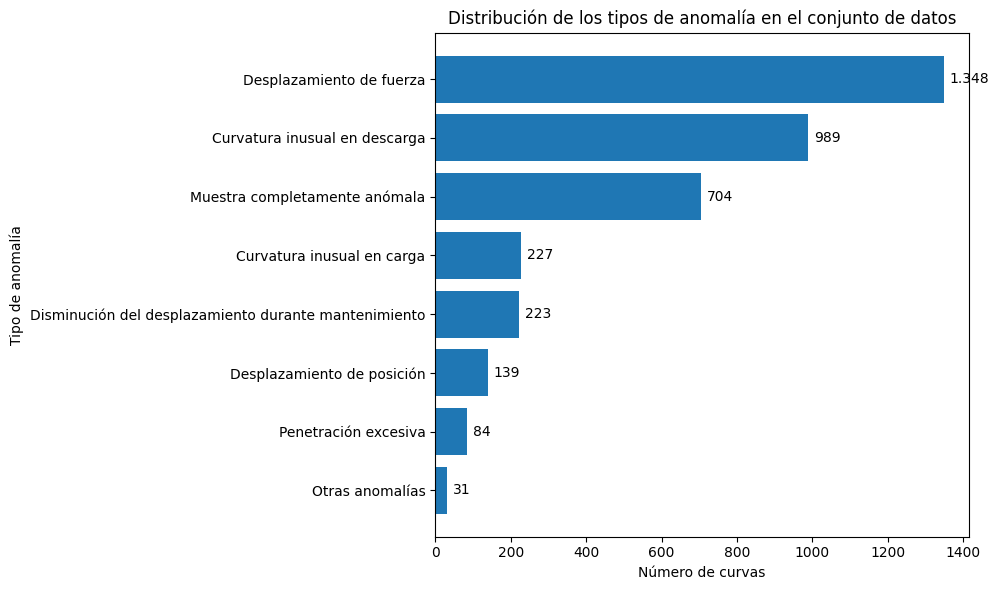

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

plot_data = anomaly_distribution.sort_values(
    "Número de curvas",
    ascending=True
)

ax.barh(
    plot_data["Categoría"],
    plot_data["Número de curvas"]
)

ax.set_xlabel("Número de curvas")
ax.set_ylabel("Tipo de anomalía")
ax.set_title(
    "Distribución de los tipos de anomalía "
    "en el conjunto de datos"
)

# Mostrar valores al final de cada barra
for i, value in enumerate(plot_data["Número de curvas"]):
    ax.text(
        value + 15,
        i,
        f"{value:,}".replace(",", "."),
        va="center"
    )

plt.tight_layout()
plt.show()

#***CELDA 14 — Exportar la figura***

In [14]:
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/14MBID_TFM/resultados"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

fig_path = OUTPUT_DIR / "TFM_02A_tipos_anomalia.png"

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_02A_tipos_anomalia.png


#***CELDA 15 — Severidad de las etiquetas***

In [15]:
severity_records = []

for col in category_cols:

    counts = (
        labels[col]
        .fillna(0)
        .value_counts()
        .sort_index()
    )

    for level, count in counts.items():

        severity_records.append({
            "Categoría": category_names[col],
            "Nivel": int(level),
            "Número de curvas": int(count)
        })

severity_df = pd.DataFrame(severity_records)

severity_positive = severity_df[
    severity_df["Nivel"] > 0
].copy()

display(severity_positive)

,Categoría,Nivel,Número de curvas
1,Muestra completamente anómala,2,704
3,Desplazamiento de fuerza,1,95
4,Desplazamiento de fuerza,2,1236
5,Desplazamiento de fuerza,3,17
7,Desplazamiento de posición,1,37
8,Desplazamiento de posición,2,101
9,Desplazamiento de posición,3,1
11,Curvatura inusual en descarga,1,58
12,Curvatura inusual en descarga,2,885
13,Curvatura inusual en descarga,3,46


#***CELDA 16 — Función para cargar curvas***



## TFM-03 — Análisis visual de curvas normales y anómalas

In [16]:
def load_curve(row):
    """
    Carga la curva carga-desplazamiento correspondiente
    a una fila de la tabla maestra.
    """
    curve_path = BASE_DIR / row["path"]
    return pd.read_csv(curve_path)


def get_representative_pair(category, level=2):
    """
    Selecciona una curva con una única anomalía de la categoría
    indicada y busca una curva normal de la misma muestra.
    """

    anomaly_mask = (
        (labels[category] == level)
        & (labels["n_anomaly_types"] == 1)
    )

    candidates = labels.loc[anomaly_mask]

    if len(candidates) == 0:
        raise ValueError(
            f"No se encontraron ejemplos para {category}"
        )

    # Buscar primero un caso cuya muestra tenga también curvas normales
    for _, anomaly_row in candidates.iterrows():

        normals_same_sample = labels[
            (labels["sample_num"] == anomaly_row["sample_num"])
            & (labels["is_anomaly"] == 0)
        ]

        if len(normals_same_sample) > 0:
            normal_row = normals_same_sample.iloc[0]
            return normal_row, anomaly_row

    # Si no existe normal de esa muestra, usar una normal global
    normal_row = labels[
        labels["is_anomaly"] == 0
    ].iloc[0]

    return normal_row, candidates.iloc[0]


print("Funciones creadas correctamente.")

Funciones creadas correctamente.


#***CELDA 17 — Comparar normal vs. force_offset***

In [17]:
normal_row, anomaly_row = get_representative_pair(
    "force_offset",
    level=2
)

normal_curve = load_curve(normal_row)
anomaly_curve = load_curve(anomaly_row)

print("CURVA NORMAL")
print(
    "Muestra:",
    normal_row["sample_num"],
    "| Indentación:",
    normal_row["indent_num"]
)

print("\nCURVA ANÓMALA")
print(
    "Muestra:",
    anomaly_row["sample_num"],
    "| Indentación:",
    anomaly_row["indent_num"]
)

print(
    "Nivel force_offset:",
    anomaly_row["force_offset"]
)

print(
    "Nota del experto:",
    anomaly_row["expert_note"]
)

CURVA NORMAL
Muestra: 2658 | Indentación: 1

CURVA ANÓMALA
Muestra: 2658 | Indentación: 14
Nivel force_offset: 2
Nota del experto: 0


#***CELDA 18 — Curva normal y anomalía de fuerza***

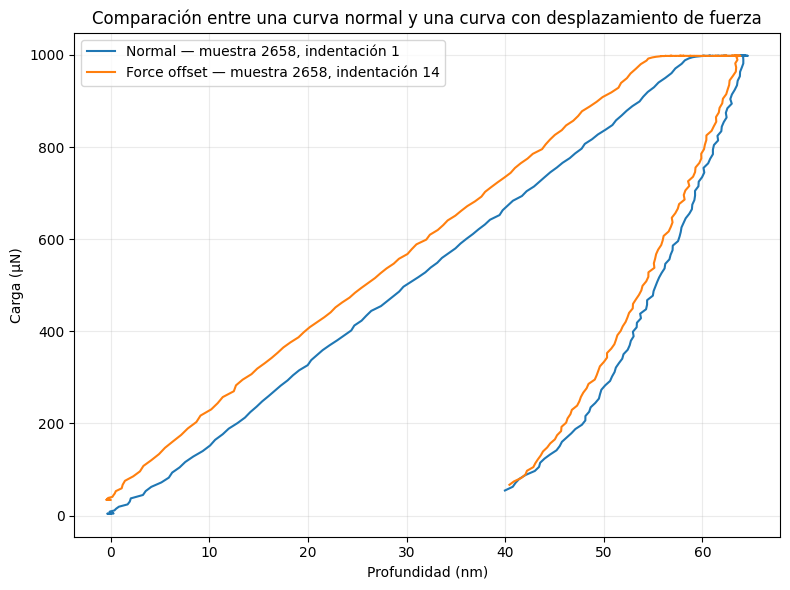

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    normal_curve["depth_nm"],
    normal_curve["load_micro_N"],
    label=(
        f"Normal — muestra {normal_row['sample_num']}, "
        f"indentación {normal_row['indent_num']}"
    )
)

ax.plot(
    anomaly_curve["depth_nm"],
    anomaly_curve["load_micro_N"],
    label=(
        f"Force offset — muestra {anomaly_row['sample_num']}, "
        f"indentación {anomaly_row['indent_num']}"
    )
)

ax.set_xlabel("Profundidad (nm)")
ax.set_ylabel("Carga (µN)")
ax.set_title(
    "Comparación entre una curva normal y una curva "
    "con desplazamiento de fuerza"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

#***CELDA 19 — Exportar***

In [19]:
fig_path = (
    OUTPUT_DIR
    / "TFM_03A_normal_vs_force_offset.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_03A_normal_vs_force_offset.png


#***CELDA 20 — Seleccionar ejemplos representativos***

In [20]:
comparison_categories = [
    "force_offset",
    "displacement_offset",
    "unusual_unloading_curvature",
    "unusual_loading_curvature",
    "tip_displacement_decreases_at_holding",
    "too_deep"
]

representative_pairs = {}

for category in comparison_categories:

    normal_row_cat, anomaly_row_cat = get_representative_pair(
        category,
        level=2
    )

    representative_pairs[category] = {
        "normal": normal_row_cat,
        "anomaly": anomaly_row_cat
    }

    print(
        category,
        "| muestra:",
        anomaly_row_cat["sample_num"],
        "| normal:",
        normal_row_cat["indent_num"],
        "| anómala:",
        anomaly_row_cat["indent_num"]
    )

force_offset | muestra: 2658 | normal: 1 | anómala: 14
displacement_offset | muestra: 4218 | normal: 1 | anómala: 12
unusual_unloading_curvature | muestra: 2678 | normal: 1 | anómala: 8
unusual_loading_curvature | muestra: 4055 | normal: 13 | anómala: 59
tip_displacement_decreases_at_holding | muestra: 2658 | normal: 1 | anómala: 0
too_deep | muestra: 2678 | normal: 1 | anómala: 38


#***CELDA 21 — Figura comparativa de anomalías***

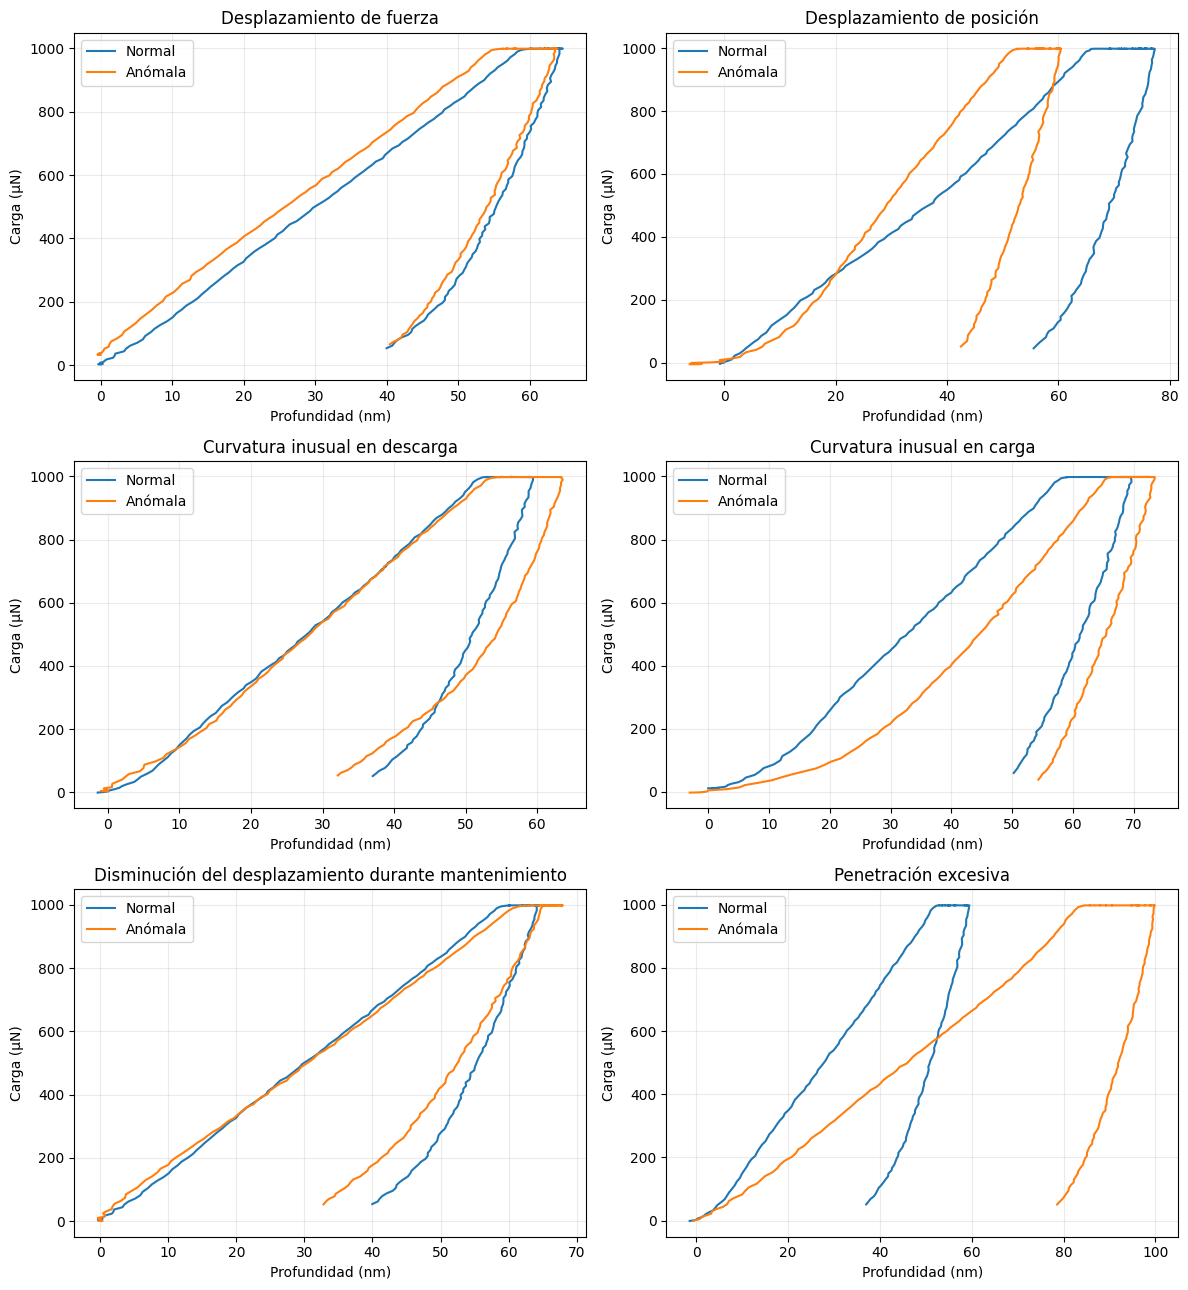

In [21]:
fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 13)
)

axes = axes.flatten()

for ax, category in zip(
    axes,
    comparison_categories
):

    normal_row_cat = (
        representative_pairs[category]["normal"]
    )

    anomaly_row_cat = (
        representative_pairs[category]["anomaly"]
    )

    normal_curve_cat = load_curve(
        normal_row_cat
    )

    anomaly_curve_cat = load_curve(
        anomaly_row_cat
    )

    ax.plot(
        normal_curve_cat["depth_nm"],
        normal_curve_cat["load_micro_N"],
        label="Normal"
    )

    ax.plot(
        anomaly_curve_cat["depth_nm"],
        anomaly_curve_cat["load_micro_N"],
        label="Anómala"
    )

    ax.set_title(
        category_names[category]
    )

    ax.set_xlabel(
        "Profundidad (nm)"
    )

    ax.set_ylabel(
        "Carga (µN)"
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend()

plt.tight_layout()
plt.show()

#***CELDA 22 — Guardar figura***

In [22]:
fig_path = (
    OUTPUT_DIR
    / "TFM_03B_comparacion_tipos_anomalia.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_03B_comparacion_tipos_anomalia.png


#***CELDA 23 — Inspeccionar la estructura temporal***

In [23]:
# ============================================================
# TFM-03C
# Inspección temporal de las fases del ensayo
# ============================================================

holding_pair = representative_pairs[
    "tip_displacement_decreases_at_holding"
]

holding_normal = load_curve(
    holding_pair["normal"]
)

holding_anomaly = load_curve(
    holding_pair["anomaly"]
)

print("CURVA NORMAL")
print(
    holding_normal[
        ["time_s", "depth_nm", "load_micro_N"]
    ].describe()
)

print("\nCURVA ANÓMALA")
print(
    holding_anomaly[
        ["time_s", "depth_nm", "load_micro_N"]
    ].describe()
)

print(
    "\nRango temporal normal:",
    holding_normal["time_s"].min(),
    "a",
    holding_normal["time_s"].max(),
    "s"
)

print(
    "Rango temporal anómala:",
    holding_anomaly["time_s"].min(),
    "a",
    holding_anomaly["time_s"].max(),
    "s"
)

CURVA NORMAL
           time_s    depth_nm  load_micro_N
count  400.000000  400.000000    400.000000
mean     0.199181   52.329972    746.661225
std      0.115429   17.360797    326.519040
min      0.000000   -0.341825      3.659489
25%      0.099590   48.113551    496.971514
50%      0.199181   61.058565    993.843964
75%      0.298772   63.877684    998.078932
max      0.398362   64.608237    998.312279

CURVA ANÓMALA
           time_s    depth_nm  load_micro_N
count  400.000000  400.000000    400.000000
mean     0.199181   53.277658    746.743087
std      0.115429   18.899770    326.407326
min      0.000000   -0.368844      1.098369
25%      0.099590   44.851574    496.948665
50%      0.199181   63.438517    993.788282
75%      0.298772   66.853201    998.095091
max      0.398362   67.968834    998.285608

Rango temporal normal: 0.0 a 0.398362 s
Rango temporal anómala: 0.0 a 0.398362 s


#***CELDA 24 — Identificar automáticamente la zona de mantenimiento***

In [24]:
def get_holding_region(curve, threshold=0.99):
    """
    Extrae los puntos correspondientes aproximadamente
    a la región de mantenimiento de carga.
    """

    max_load = curve["load_micro_N"].max()

    hold = curve[
        curve["load_micro_N"] >= threshold * max_load
    ].copy()

    return hold


normal_hold = get_holding_region(
    holding_normal
)

anomaly_hold = get_holding_region(
    holding_anomaly
)

print(
    "Puntos de mantenimiento — normal:",
    len(normal_hold)
)

print(
    "Puntos de mantenimiento — anómala:",
    len(anomaly_hold)
)

print("\nNormal:")
display(
    normal_hold[
        ["time_s", "depth_nm", "load_micro_N"]
    ].head()
)

print("\nAnómala:")
display(
    anomaly_hold[
        ["time_s", "depth_nm", "load_micro_N"]
    ].head()
)

Puntos de mantenimiento — normal: 203
Puntos de mantenimiento — anómala: 203

Normal:


,time_s,depth_nm,load_micro_N
100,0.099840,58.222916,988.431636
101,0.100838,58.630396,992.663442
102,0.101837,58.988591,995.024486
103,0.102835,59.342454,996.332761
104,0.103834,59.689575,997.025888



Anómala:


,time_s,depth_nm,load_micro_N
100,0.099840,60.569284,988.418489
101,0.100838,61.179817,992.570042
102,0.101837,61.528736,995.006522
103,0.102835,61.892809,996.293058
104,0.103834,62.095437,997.071819


#***CELDA 25 — Zoom de la anomalía durante mantenimiento***

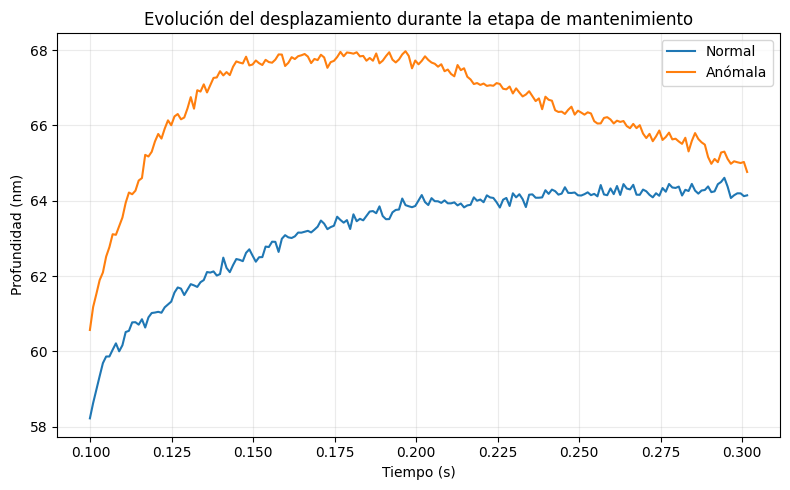

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    normal_hold["time_s"],
    normal_hold["depth_nm"],
    label="Normal"
)

ax.plot(
    anomaly_hold["time_s"],
    anomaly_hold["depth_nm"],
    label="Anómala"
)

ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Profundidad (nm)")
ax.set_title(
    "Evolución del desplazamiento durante "
    "la etapa de mantenimiento"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

#***CELDA 26 — Cuantificar el cambio durante mantenimiento***

In [26]:
def holding_depth_change(hold_curve):
    """
    Cambio de profundidad entre el inicio y el final
    de la región de mantenimiento.
    """

    return (
        hold_curve["depth_nm"].iloc[-1]
        - hold_curve["depth_nm"].iloc[0]
    )


normal_change = holding_depth_change(
    normal_hold
)

anomaly_change = holding_depth_change(
    anomaly_hold
)

print(
    "Cambio de profundidad — normal:",
    round(normal_change, 4),
    "nm"
)

print(
    "Cambio de profundidad — anómala:",
    round(anomaly_change, 4),
    "nm"
)

Cambio de profundidad — normal: 5.9198 nm
Cambio de profundidad — anómala: 4.1939 nm


#***CELDA 27 — Exportar TFM-03C***

In [27]:
fig_path = (
    OUTPUT_DIR
    / "TFM_03C_mantenimiento_normal_anomalo.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_03C_mantenimiento_normal_anomalo.png


#***CELDA 28 — Resumen por muestra***

TFM-04 — Distribución de anomalías por muestra

In [28]:
# ============================================================
# TFM-04
# Distribución de anomalías por muestra
# ============================================================

sample_summary = (
    labels
    .groupby("sample_num")
    .agg(
        total_curves=("indent_num", "size"),
        anomalous_curves=("is_anomaly", "sum")
    )
    .reset_index()
)

sample_summary["normal_curves"] = (
    sample_summary["total_curves"]
    - sample_summary["anomalous_curves"]
)

sample_summary["anomaly_percentage"] = (
    sample_summary["anomalous_curves"]
    / sample_summary["total_curves"]
    * 100
)

display(sample_summary.head())

print("\nNúmero de muestras:", len(sample_summary))

print(
    "Mínimo de curvas anómalas por muestra:",
    sample_summary["anomalous_curves"].min()
)

print(
    "Máximo de curvas anómalas por muestra:",
    sample_summary["anomalous_curves"].max()
)

print(
    "Mediana:",
    sample_summary["anomalous_curves"].median()
)

print(
    "Media:",
    round(
        sample_summary["anomalous_curves"].mean(),
        2
    )
)

,sample_num,total_curves,anomalous_curves,normal_curves,anomaly_percentage
0,2658,64,22,42,34.3750
1,2666,64,27,37,42.1875
2,2670,64,22,42,34.3750
3,2678,64,18,46,28.1250
4,2686,64,24,40,37.5000



Número de muestras: 150
Mínimo de curvas anómalas por muestra: 8
Máximo de curvas anómalas por muestra: 64
Mediana: 20.0
Media: 22.73


#***CELDA 29 — Casos extremos***

In [29]:
samples_without_anomalies = (
    sample_summary["anomalous_curves"] == 0
).sum()

fully_anomalous_samples = (
    sample_summary["anomalous_curves"]
    == sample_summary["total_curves"]
).sum()

print(
    "Muestras sin curvas anómalas:",
    samples_without_anomalies
)

print(
    "Muestras con las 64 curvas anómalas:",
    fully_anomalous_samples
)

print("\nMuestras completamente anómalas:")

display(
    sample_summary[
        sample_summary["anomalous_curves"]
        == sample_summary["total_curves"]
    ]
)

Muestras sin curvas anómalas: 0
Muestras con las 64 curvas anómalas: 11

Muestras completamente anómalas:


,sample_num,total_curves,anomalous_curves,normal_curves,anomaly_percentage
14,4141,64,64,0,100.0
15,4147,64,64,0,100.0
16,4154,64,64,0,100.0
17,4158,64,64,0,100.0
26,4267,64,64,0,100.0
27,4273,64,64,0,100.0
28,4279,64,64,0,100.0
33,5946,64,64,0,100.0
54,6132,64,64,0,100.0
56,6146,64,64,0,100.0


#***CELDA 30 — Distribución gráfica por muestra***

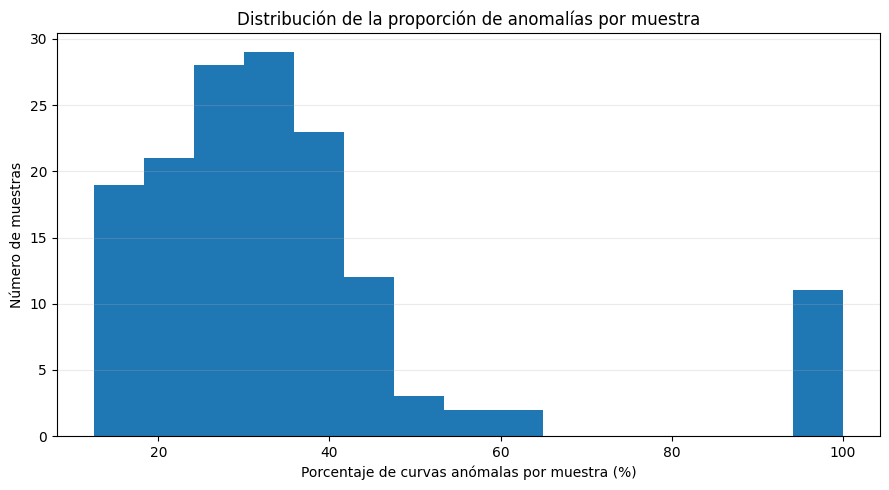

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    sample_summary["anomaly_percentage"],
    bins=15
)

ax.set_xlabel(
    "Porcentaje de curvas anómalas por muestra (%)"
)

ax.set_ylabel(
    "Número de muestras"
)

ax.set_title(
    "Distribución de la proporción de anomalías por muestra"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

#***CELDA 31 — Comprobación clave para la futura partición***

In [31]:
print(
    "Muestras con al menos una curva normal:",
    (sample_summary["normal_curves"] > 0).sum()
)

print(
    "Muestras con al menos una curva anómala:",
    (sample_summary["anomalous_curves"] > 0).sum()
)

print(
    "Muestras con ambas clases:",
    (
        (sample_summary["normal_curves"] > 0)
        &
        (sample_summary["anomalous_curves"] > 0)
    ).sum()
)

Muestras con al menos una curva normal: 139
Muestras con al menos una curva anómala: 150
Muestras con ambas clases: 139


#***CELDA 32 — Exportar figura TFM-04A***

In [32]:
fig_path = (
    OUTPUT_DIR
    / "TFM_04A_distribucion_anomalias_por_muestra.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_04A_distribucion_anomalias_por_muestra.png


#***CELDA 33 — Versión de scikit-learn***

# TFM-05 — Estrategia de partición agrupada del conjunto de datos

In [33]:
import sklearn
from sklearn.model_selection import StratifiedGroupKFold

print("Versión de scikit-learn:", sklearn.__version__)

Versión de scikit-learn: 1.6.1


#***CELDA 34 — Crear cinco folds agrupados y estratificados***

In [34]:
# @title
# ============================================================
# TFM-05
# Validación de una partición estratificada por muestra
# ============================================================

X_dummy = np.zeros((len(labels), 1))

y = labels["is_anomaly"].to_numpy()

groups = labels["sample_num"].to_numpy()

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

fold_records = []
fold_indices = {}

for fold, (train_idx, test_idx) in enumerate(
    sgkf.split(
        X_dummy,
        y,
        groups
    ),
    start=1
):

    train_groups = set(
        labels.iloc[train_idx]["sample_num"]
    )

    test_groups = set(
        labels.iloc[test_idx]["sample_num"]
    )

    # Verificación crítica:
    # ninguna muestra puede estar simultáneamente
    # en entrenamiento y prueba
    overlap = train_groups.intersection(
        test_groups
    )

    assert len(overlap) == 0

    test_fold = labels.iloc[test_idx]

    n_test_samples = (
        test_fold["sample_num"]
        .nunique()
    )

    normal_count = (
        test_fold["is_anomaly"] == 0
    ).sum()

    anomaly_count = (
        test_fold["is_anomaly"] == 1
    ).sum()

    anomaly_pct = (
        anomaly_count
        / len(test_fold)
        * 100
    )

    # Número de muestras completamente anómalas
    fully_anomalous_in_fold = (
        sample_summary[
            sample_summary["sample_num"].isin(
                test_groups
            )
        ]["normal_curves"]
        .eq(0)
        .sum()
    )

    fold_records.append({
        "Fold": fold,
        "Muestras": n_test_samples,
        "Curvas": len(test_fold),
        "Normales": normal_count,
        "Anómalas": anomaly_count,
        "% anómalas": round(
            anomaly_pct,
            2
        ),
        "Muestras 100 % anómalas":
            int(fully_anomalous_in_fold)
    })

    fold_indices[fold] = {
        "train_idx": train_idx,
        "test_idx": test_idx
    }


fold_summary = pd.DataFrame(
    fold_records
)

display(fold_summary)

,Fold,Muestras,Curvas,Normales,Anómalas,% anómalas,Muestras 100 % anómalas
0,1,30,1920,1248,672,35.00,1
1,2,30,1920,1255,665,34.64,3
2,3,30,1920,1229,691,35.99,2
3,4,30,1920,1152,768,40.00,4
4,5,30,1920,1307,613,31.93,1


#***CELDA 35 — Comparación con la distribución global***

In [35]:
global_anomaly_pct = (
    labels["is_anomaly"].mean()
    * 100
)

print(
    "Porcentaje global de anomalías:",
    round(global_anomaly_pct, 2),
    "%"
)

fold_summary["Diferencia vs. global (pp)"] = (
    fold_summary["% anómalas"]
    - global_anomaly_pct
).round(2)

display(fold_summary)

Porcentaje global de anomalías: 35.51 %


,Fold,Muestras,Curvas,Normales,Anómalas,% anómalas,Muestras 100 % anómalas,Diferencia vs. global (pp)
0,1,30,1920,1248,672,35.00,1,-0.51
1,2,30,1920,1255,665,34.64,3,-0.87
2,3,30,1920,1229,691,35.99,2,0.48
3,4,30,1920,1152,768,40.00,4,4.49
4,5,30,1920,1307,613,31.93,1,-3.58


#***CELDA 36 — Comprobar que cada muestra aparece una sola vez en test***

In [36]:
# @title
test_group_occurrences = {}

for fold, indices in fold_indices.items():

    fold_groups = (
        labels.iloc[
            indices["test_idx"]
        ]["sample_num"]
        .unique()
    )

    for group in fold_groups:

        test_group_occurrences[group] = (
            test_group_occurrences.get(
                group,
                0
            )
            + 1
        )


occurrences = pd.Series(
    test_group_occurrences
)

print(
    "Número de muestras evaluadas:",
    len(occurrences)
)

print(
    "Mínimo de apariciones como test:",
    occurrences.min()
)

print(
    "Máximo de apariciones como test:",
    occurrences.max()
)

Número de muestras evaluadas: 150
Mínimo de apariciones como test: 1
Máximo de apariciones como test: 1


#***CELDA 37 — Auditoría de categorías del test final***

In [37]:
# @title
# ============================================================
# TFM-05
# Auditoría final del conjunto de test candidato
# ============================================================

FINAL_TEST_FOLD = 1

test_idx = fold_indices[FINAL_TEST_FOLD]["test_idx"]
dev_idx = fold_indices[FINAL_TEST_FOLD]["train_idx"]

test_candidate = labels.iloc[test_idx].copy()
dev_candidate = labels.iloc[dev_idx].copy()

audit_records = []

for col in category_cols:

    global_presence = labels[col].fillna(0).gt(0)
    test_presence = test_candidate[col].fillna(0).gt(0)

    audit_records.append({
        "Categoría": category_names[col],
        "Global": int(global_presence.sum()),
        "Test": int(test_presence.sum()),
        "% global": round(
            global_presence.mean() * 100,
            2
        ),
        "% test": round(
            test_presence.mean() * 100,
            2
        )
    })

# Categoría "other"
global_other = (
    labels["other"]
    .fillna("0")
    .astype(str)
    .str.strip()
    .ne("0")
)

test_other = (
    test_candidate["other"]
    .fillna("0")
    .astype(str)
    .str.strip()
    .ne("0")
)

audit_records.append({
    "Categoría": "Otras anomalías",
    "Global": int(global_other.sum()),
    "Test": int(test_other.sum()),
    "% global": round(
        global_other.mean() * 100,
        2
    ),
    "% test": round(
        test_other.mean() * 100,
        2
    )
})

test_category_audit = pd.DataFrame(
    audit_records
)

test_category_audit[
    "Diferencia test-global (pp)"
] = (
    test_category_audit["% test"]
    - test_category_audit["% global"]
).round(2)

display(test_category_audit)

,Categoría,Global,Test,% global,% test,Diferencia test-global (pp)
0,Muestra completamente anómala,704,64,7.33,3.33,-4.00
1,Desplazamiento de fuerza,1348,296,14.04,15.42,1.38
2,Desplazamiento de posición,139,17,1.45,0.89,-0.56
3,Curvatura inusual en descarga,989,205,10.30,10.68,0.38
4,Curvatura inusual en carga,227,69,2.36,3.59,1.23
5,Disminución del desplazamiento durante manteni...,223,42,2.32,2.19,-0.13
6,Penetración excesiva,84,13,0.88,0.68,-0.20
7,Otras anomalías,31,9,0.32,0.47,0.15


#***CELDA 38 — Congelar el test final***

In [38]:
# @title
# ============================================================
# CONGELACIÓN DEL TEST FINAL
# ============================================================

dev_labels = labels.iloc[dev_idx].copy()
test_labels = labels.iloc[test_idx].copy()

print("DESARROLLO")
print("Muestras:", dev_labels["sample_num"].nunique())
print("Curvas:", len(dev_labels))
print(
    "Normales:",
    (dev_labels["is_anomaly"] == 0).sum()
)
print(
    "Anómalas:",
    (dev_labels["is_anomaly"] == 1).sum()
)
print(
    "% anómalas:",
    round(dev_labels["is_anomaly"].mean() * 100, 2)
)

print("\nTEST FINAL")
print("Muestras:", test_labels["sample_num"].nunique())
print("Curvas:", len(test_labels))
print(
    "Normales:",
    (test_labels["is_anomaly"] == 0).sum()
)
print(
    "Anómalas:",
    (test_labels["is_anomaly"] == 1).sum()
)
print(
    "% anómalas:",
    round(test_labels["is_anomaly"].mean() * 100, 2)
)

# Comprobación de fuga entre grupos
dev_samples = set(dev_labels["sample_num"])
test_samples = set(test_labels["sample_num"])

overlap = dev_samples.intersection(test_samples)

print(
    "\nMuestras compartidas desarrollo-test:",
    len(overlap)
)

assert len(overlap) == 0
assert len(dev_labels) + len(test_labels) == len(labels)

DESARROLLO
Muestras: 120
Curvas: 7680
Normales: 4943
Anómalas: 2737
% anómalas: 35.64

TEST FINAL
Muestras: 30
Curvas: 1920
Normales: 1248
Anómalas: 672
% anómalas: 35.0

Muestras compartidas desarrollo-test: 0


#***CELDA 39 — Guardar el manifiesto de partición***

In [39]:
# @title
split_manifest = (
    labels[
        [
            "sample_num",
            "indent_num",
            "path",
            "is_anomaly"
        ]
    ]
    .copy()
)

test_samples = set(
    test_labels["sample_num"].unique()
)

split_manifest["split"] = (
    split_manifest["sample_num"]
    .apply(
        lambda x:
        "test"
        if x in test_samples
        else "development"
    )
)

manifest_path = (
    OUTPUT_DIR
    / "TFM_split_manifest_seed42.csv"
)

split_manifest.to_csv(
    manifest_path,
    index=False
)

print("Manifiesto guardado:")
print(manifest_path)

print("\nDistribución:")
print(
    split_manifest["split"]
    .value_counts()
)

Manifiesto guardado:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_split_manifest_seed42.csv

Distribución:
split
development    7680
test           1920
Name: count, dtype: int64


#***CELDA 40 — Cargar las curvas de desarrollo***

## TFM-06 — Construcción y validación de la representación numérica de las curvas

In [40]:
# @title
# ============================================================
# TFM-06
# Construcción de matrices numéricas
# SOLO conjunto de desarrollo
# ============================================================

dev_meta = (
    dev_labels[
        [
            "sample_num",
            "indent_num",
            "is_anomaly",
            "path"
        ]
    ]
    .reset_index(drop=True)
    .copy()
)

N_POINTS = 400
n_dev = len(dev_meta)

X_depth_dev = np.empty(
    (n_dev, N_POINTS),
    dtype=np.float32
)

X_load_dev = np.empty(
    (n_dev, N_POINTS),
    dtype=np.float32
)

time_reference = None
same_time_grid = True

for i, rel_path in enumerate(dev_meta["path"]):

    curve = pd.read_csv(
        BASE_DIR / rel_path,
        usecols=[
            "depth_nm",
            "load_micro_N",
            "time_s"
        ]
    )

    if len(curve) != N_POINTS:
        raise ValueError(
            f"Curva {rel_path}: "
            f"{len(curve)} puntos en lugar de {N_POINTS}"
        )

    depth = curve["depth_nm"].to_numpy(
        dtype=np.float32
    )

    load = curve["load_micro_N"].to_numpy(
        dtype=np.float32
    )

    time = curve["time_s"].to_numpy(
        dtype=np.float32
    )

    if (
        np.isnan(depth).any()
        or np.isnan(load).any()
        or np.isnan(time).any()
    ):
        raise ValueError(
            f"Valores NaN detectados en {rel_path}"
        )

    X_depth_dev[i] = depth
    X_load_dev[i] = load

    if time_reference is None:
        time_reference = time.copy()

    elif not np.allclose(
        time,
        time_reference,
        rtol=0,
        atol=1e-6
    ):
        same_time_grid = False


print("Curvas cargadas:", n_dev)

print(
    "Matriz profundidad:",
    X_depth_dev.shape
)

print(
    "Matriz carga:",
    X_load_dev.shape
)

print(
    "Misma malla temporal:",
    same_time_grid
)

print(
    "Rango temporal:",
    round(float(time_reference.min()), 6),
    "a",
    round(float(time_reference.max()), 6),
    "s"
)

Curvas cargadas: 7680
Matriz profundidad: (7680, 400)
Matriz carga: (7680, 400)
Misma malla temporal: True
Rango temporal: 0.0 a 0.398362 s


#***CELDA 41 — Crear la representación secuencial completa***

In [41]:
# @title
# Representación completa de cada curva:
# [depth_0 ... depth_399 | load_0 ... load_399]

X_curve_dev = np.concatenate(
    [
        X_depth_dev,
        X_load_dev
    ],
    axis=1
)

y_dev = (
    dev_meta["is_anomaly"]
    .to_numpy(dtype=np.int8)
)

groups_dev = (
    dev_meta["sample_num"]
    .to_numpy()
)

indent_dev = (
    dev_meta["indent_num"]
    .to_numpy()
)

print(
    "Matriz de curvas:",
    X_curve_dev.shape
)

print(
    "Vector objetivo:",
    y_dev.shape
)

print(
    "Vector de grupos:",
    groups_dev.shape
)

print(
    "Número de muestras físicas:",
    len(np.unique(groups_dev))
)

print(
    "Número de variables por curva:",
    X_curve_dev.shape[1]
)

Matriz de curvas: (7680, 800)
Vector objetivo: (7680,)
Vector de grupos: (7680,)
Número de muestras físicas: 120
Número de variables por curva: 800


#***CELDA 42 — Revisar las escalas originales***

In [42]:
# @title
raw_scale_summary = pd.DataFrame({
    "Variable": [
        "Profundidad (nm)",
        "Carga (µN)"
    ],
    "Mínimo": [
        float(X_depth_dev.min()),
        float(X_load_dev.min())
    ],
    "Máximo": [
        float(X_depth_dev.max()),
        float(X_load_dev.max())
    ],
    "Media": [
        float(X_depth_dev.mean()),
        float(X_load_dev.mean())
    ],
    "Desviación estándar": [
        float(X_depth_dev.std()),
        float(X_load_dev.std())
    ]
})

display(
    raw_scale_summary.round(4)
)

,Variable,Mínimo,Máximo,Media,Desviación estándar
0,Profundidad (nm),-180.1523,2345.5649,86.7894,134.8664
1,Carga (µN),-6.6890,998.7858,746.8438,325.8448


#***CELDA 43 — Características básicas de cada curva***

In [43]:
# @title
curve_basic_features = pd.DataFrame({
    "sample_num": groups_dev,
    "indent_num": indent_dev,
    "is_anomaly": y_dev,

    "initial_depth_nm":
        X_depth_dev[:, 0],

    "initial_load_micro_N":
        X_load_dev[:, 0],

    "max_depth_nm":
        X_depth_dev.max(axis=1),

    "max_load_micro_N":
        X_load_dev.max(axis=1),

    "final_depth_nm":
        X_depth_dev[:, -1],

    "final_load_micro_N":
        X_load_dev[:, -1]
})

display(
    curve_basic_features.head()
)

print("\nResumen:")
display(
    curve_basic_features[
        [
            "initial_depth_nm",
            "initial_load_micro_N",
            "max_depth_nm",
            "max_load_micro_N",
            "final_depth_nm",
            "final_load_micro_N"
        ]
    ]
    .describe()
    .round(3)
)

,sample_num,indent_num,is_anomaly,initial_depth_nm,initial_load_micro_N,max_depth_nm,max_load_micro_N,final_depth_nm,final_load_micro_N
0,2658,0,1,0.310378,1.098369,67.968834,998.285583,32.817551,53.538761
1,2658,1,0,0.000000,3.659489,64.608238,998.312256,39.974380,54.313499
2,2658,2,0,-0.643130,-0.252815,64.174690,998.279785,41.806541,54.103680
3,2658,3,0,-0.388710,1.675628,77.587288,998.260864,56.318890,55.549202
4,2658,4,0,0.000000,3.040848,80.212143,998.305237,59.305992,57.254871



Resumen:


,initial_depth_nm,initial_load_micro_N,max_depth_nm,max_load_micro_N,final_depth_nm,final_load_micro_N
count,7680.000,7680.000,7680.000,7680.000,7680.000,7680.000
mean,-1.729,10.232,104.206,998.368,80.458,52.735
std,8.253,33.309,141.289,0.085,135.601,21.382
min,-180.152,-6.689,0.000,998.060,-86.292,15.240
25%,-0.927,-0.549,68.583,998.329,46.741,46.120
50%,-0.325,0.556,77.914,998.370,56.187,49.840
75%,0.000,2.761,90.490,998.413,68.291,55.374
max,10.762,832.282,2345.565,998.786,2295.698,864.572


#***CELDA 44 — Guardar las matrices de desarrollo***

In [44]:
# @title
matrix_path = (
    OUTPUT_DIR
    / "TFM_dev_curves_raw_seed42.npz"
)

np.savez_compressed(
    matrix_path,

    depth=X_depth_dev,
    load=X_load_dev,

    y=y_dev,

    sample_num=groups_dev,
    indent_num=indent_dev,

    time=time_reference
)

print(
    "Matrices guardadas en:"
)

print(matrix_path)

print(
    "\nTamaño aproximado en memoria:"
)

memory_mb = (
    X_depth_dev.nbytes
    + X_load_dev.nbytes
) / (1024 ** 2)

print(
    f"{memory_mb:.2f} MB"
)

Matrices guardadas en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_dev_curves_raw_seed42.npz

Tamaño aproximado en memoria:
23.44 MB


#***CELDA 45 — Identificar las fases del ensayo***

## TFM-07 — Construcción de características físicas y geométricas

In [45]:
# @title
# ============================================================
# TFM-07
# Identificación de las fases del ensayo
# ============================================================

t = time_reference

# Final aproximado de carga: 0.1 s
idx_load_end = np.argmin(
    np.abs(t - 0.1)
)

# Final aproximado de mantenimiento: 0.3 s
idx_hold_end = np.argmin(
    np.abs(t - 0.3)
)

loading_idx = np.arange(
    0,
    idx_load_end + 1
)

holding_idx = np.arange(
    idx_load_end,
    idx_hold_end + 1
)

unloading_idx = np.arange(
    idx_hold_end,
    len(t)
)

print(
    "Fin de carga:",
    idx_load_end,
    "->",
    t[idx_load_end],
    "s"
)

print(
    "Fin de mantenimiento:",
    idx_hold_end,
    "->",
    t[idx_hold_end],
    "s"
)

print(
    "\nPuntos fase de carga:",
    len(loading_idx)
)

print(
    "Puntos mantenimiento:",
    len(holding_idx)
)

print(
    "Puntos descarga:",
    len(unloading_idx)
)

Fin de carga: 100 -> 0.09984 s
Fin de mantenimiento: 300 -> 0.29952 s

Puntos fase de carga: 101
Puntos mantenimiento: 201
Puntos descarga: 100


#***CELDA 46 — Función de extracción de características***

In [46]:
# @title
def depth_at_load_fraction(
    depth,
    load,
    indices,
    fraction
):
    """
    Devuelve la profundidad correspondiente al punto
    cuya carga se aproxima más a una fracción
    determinada de la carga máxima.
    """

    target_load = fraction * np.max(load)

    local_load = load[indices]

    nearest_local = np.argmin(
        np.abs(local_load - target_load)
    )

    idx = indices[nearest_local]

    return float(depth[idx])


def extract_curve_features(
    depth,
    load,
    time
):
    """
    Extrae características físicas y geométricas
    de una curva carga-profundidad.
    """

    # Información inicial
    initial_depth = depth[0]
    initial_load = load[0]

    mean_initial_depth = np.mean(
        depth[:5]
    )

    mean_initial_load = np.mean(
        load[:5]
    )

    # Valores globales
    max_depth = np.max(depth)
    min_depth = np.min(depth)

    final_depth = depth[-1]
    final_load = load[-1]

    depth_span = (
        max_depth - min_depth
    )

    # --------------------------------------------------------
    # Mantenimiento
    # --------------------------------------------------------

    hold_depth = depth[
        holding_idx
    ]

    hold_time = time[
        holding_idx
    ]

    hold_delta_depth = (
        hold_depth[-1]
        - hold_depth[0]
    )

    # Pendiente profundidad-tiempo durante mantenimiento
    hold_slope = np.polyfit(
        hold_time,
        hold_depth,
        1
    )[0]

    # --------------------------------------------------------
    # Forma de la rama de carga
    # --------------------------------------------------------

    load_depth_25 = depth_at_load_fraction(
        depth,
        load,
        loading_idx,
        0.25
    )

    load_depth_50 = depth_at_load_fraction(
        depth,
        load,
        loading_idx,
        0.50
    )

    load_depth_75 = depth_at_load_fraction(
        depth,
        load,
        loading_idx,
        0.75
    )

    load_depth_90 = depth_at_load_fraction(
        depth,
        load,
        loading_idx,
        0.90
    )

    # --------------------------------------------------------
    # Forma de la rama de descarga
    # --------------------------------------------------------

    unload_depth_90 = depth_at_load_fraction(
        depth,
        load,
        unloading_idx,
        0.90
    )

    unload_depth_75 = depth_at_load_fraction(
        depth,
        load,
        unloading_idx,
        0.75
    )

    unload_depth_50 = depth_at_load_fraction(
        depth,
        load,
        unloading_idx,
        0.50
    )

    unload_depth_25 = depth_at_load_fraction(
        depth,
        load,
        unloading_idx,
        0.25
    )

    return {
        "initial_depth_nm":
            float(initial_depth),

        "initial_load_uN":
            float(initial_load),

        "mean_initial_depth_5_nm":
            float(mean_initial_depth),

        "mean_initial_load_5_uN":
            float(mean_initial_load),

        "max_depth_nm":
            float(max_depth),

        "min_depth_nm":
            float(min_depth),

        "final_depth_nm":
            float(final_depth),

        "final_load_uN":
            float(final_load),

        "depth_span_nm":
            float(depth_span),

        "hold_delta_depth_nm":
            float(hold_delta_depth),

        "hold_depth_slope_nm_s":
            float(hold_slope),

        "loading_depth_25pct_nm":
            load_depth_25,

        "loading_depth_50pct_nm":
            load_depth_50,

        "loading_depth_75pct_nm":
            load_depth_75,

        "loading_depth_90pct_nm":
            load_depth_90,

        "unloading_depth_90pct_nm":
            unload_depth_90,

        "unloading_depth_75pct_nm":
            unload_depth_75,

        "unloading_depth_50pct_nm":
            unload_depth_50,

        "unloading_depth_25pct_nm":
            unload_depth_25
    }

#***CELDA 47 — Construir Representación B***

In [47]:
# @title
feature_rows = []

for i in range(len(dev_meta)):

    features = extract_curve_features(
        X_depth_dev[i],
        X_load_dev[i],
        time_reference
    )

    feature_rows.append(features)


X_features_dev_df = pd.DataFrame(
    feature_rows
)

print(
    "Dimensiones de Representación B:",
    X_features_dev_df.shape
)

print(
    "Valores NaN:",
    X_features_dev_df
    .isna()
    .sum()
    .sum()
)

print(
    "Valores infinitos:",
    np.isinf(
        X_features_dev_df.to_numpy()
    ).sum()
)

display(
    X_features_dev_df.head()
)

Dimensiones de Representación B: (7680, 19)
Valores NaN: 0
Valores infinitos: 0


,initial_depth_nm,initial_load_uN,mean_initial_depth_5_nm,mean_initial_load_5_uN,max_depth_nm,min_depth_nm,final_depth_nm,final_load_uN,depth_span_nm,hold_delta_depth_nm,hold_depth_slope_nm_s,loading_depth_25pct_nm,loading_depth_50pct_nm,loading_depth_75pct_nm,loading_depth_90pct_nm,unloading_depth_90pct_nm,unloading_depth_75pct_nm,unloading_depth_50pct_nm,unloading_depth_25pct_nm
0,0.310378,1.098369,0.053928,3.307853,67.968834,-0.368844,32.817551,53.538761,68.337677,4.431282,1.316375,14.319150,30.216351,45.600601,54.943951,63.068462,59.323242,52.414646,43.932823
1,0.000000,3.659489,-0.004499,5.271952,64.608238,-0.341825,39.974380,54.313499,64.950066,5.972260,20.402483,15.368312,29.688810,44.574963,53.622307,62.969856,60.183971,55.226654,49.502834
2,-0.643130,-0.252815,-0.237482,1.629952,64.174690,-0.643130,41.806541,54.103680,64.817818,7.711990,31.797887,15.276775,30.441242,44.250191,52.258518,62.347095,60.065422,55.461849,49.670021
3,-0.388710,1.675628,-0.148395,2.796178,77.587288,-0.388710,56.318890,55.549202,77.975998,11.767975,52.416241,17.398474,34.616566,50.327053,60.629379,75.975471,73.330338,68.631821,62.708065
4,0.000000,3.040848,0.181403,3.390044,80.212143,0.000000,59.305992,57.254871,80.212143,11.908760,49.942563,19.980650,36.441193,53.398567,62.822731,78.538284,75.909050,71.071548,65.428612


#***CELDA 48 — Comprobar la variabilidad de las características***

In [48]:
# @title
feature_variability = pd.DataFrame({
    "Característica":
        X_features_dev_df.columns,

    "Media":
        X_features_dev_df.mean().values,

    "Desviación estándar":
        X_features_dev_df.std().values,

    "Mínimo":
        X_features_dev_df.min().values,

    "Máximo":
        X_features_dev_df.max().values
})

display(
    feature_variability
    .round(4)
)

,Característica,Media,Desviación estándar,Mínimo,Máximo
0,initial_depth_nm,-1.7287,8.2529,-180.1523,10.7621
1,initial_load_uN,10.2318,33.3087,-6.6890,832.2821
2,mean_initial_depth_5_nm,-1.0563,7.8480,-172.2348,34.3158
3,mean_initial_load_5_uN,12.3251,32.6522,-5.5608,832.8116
4,max_depth_nm,104.2059,141.2890,0.0000,2345.5649
5,min_depth_nm,-2.0347,8.3040,-180.1523,0.0000
6,final_depth_nm,80.4580,135.6010,-86.2918,2295.6982
7,final_load_uN,52.7346,21.3824,15.2403,864.5716
8,depth_span_nm,106.2407,143.9562,25.1732,2350.3254
9,hold_delta_depth_nm,12.0452,9.3686,-28.0556,328.9393


#***CELDA 49 — Comprobación específica de características clave***

In [49]:
# @title
features_for_check = [
    "initial_load_uN",
    "initial_depth_nm",
    "max_depth_nm",
    "hold_delta_depth_nm",
    "hold_depth_slope_nm_s"
]

feature_check = (
    X_features_dev_df[
        features_for_check
    ]
    .copy()
)

feature_check["is_anomaly"] = y_dev

summary_by_class = (
    feature_check
    .groupby("is_anomaly")
    [features_for_check]
    .median()
    .T
)

summary_by_class.columns = [
    "Mediana normal",
    "Mediana anómala"
]

display(
    summary_by_class.round(4)
)

,Mediana normal,Mediana anómala
initial_load_uN,0.2382,4.8281
initial_depth_nm,-0.4684,0.0000
max_depth_nm,76.7074,81.8148
hold_delta_depth_nm,9.7314,12.8033
hold_depth_slope_nm_s,41.1499,54.5671


#***CELDA 50 — Guardar Representación B***

##TFM-08 — Validación interna y primer modelo base

In [50]:
# @title
# ============================================================
# Guardar Representación B
# ============================================================

features_path = (
    OUTPUT_DIR
    / "TFM_dev_features_B_seed42.csv"
)

features_to_save = (
    X_features_dev_df.copy()
)

features_to_save.insert(
    0,
    "is_anomaly",
    y_dev
)

features_to_save.insert(
    0,
    "indent_num",
    indent_dev
)

features_to_save.insert(
    0,
    "sample_num",
    groups_dev
)

features_to_save.to_csv(
    features_path,
    index=False
)

print("Representación B guardada en:")
print(features_path)

Representación B guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_dev_features_B_seed42.csv


#***CELDA 51 — Crear la validación cruzada interna***

In [51]:
# @title
# ============================================================
# TFM-08
# Validación cruzada interna
# SOLO conjunto de desarrollo
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold

inner_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

internal_folds = {}
internal_records = []

X_dummy_dev = np.zeros(
    (len(y_dev), 1)
)

for fold, (train_idx, val_idx) in enumerate(
    inner_cv.split(
        X_dummy_dev,
        y_dev,
        groups_dev
    ),
    start=1
):

    train_groups = set(
        groups_dev[train_idx]
    )

    val_groups = set(
        groups_dev[val_idx]
    )

    overlap = train_groups.intersection(
        val_groups
    )

    assert len(overlap) == 0

    y_train_fold = y_dev[train_idx]
    y_val_fold = y_dev[val_idx]

    internal_records.append({
        "Fold": fold,

        "Muestras entrenamiento":
            len(train_groups),

        "Muestras validación":
            len(val_groups),

        "Curvas entrenamiento":
            len(train_idx),

        "Curvas validación":
            len(val_idx),

        "% anomalías entrenamiento":
            round(
                y_train_fold.mean() * 100,
                2
            ),

        "% anomalías validación":
            round(
                y_val_fold.mean() * 100,
                2
            )
    })

    internal_folds[fold] = {
        "train_idx": train_idx,
        "val_idx": val_idx
    }


internal_cv_summary = pd.DataFrame(
    internal_records
)

display(
    internal_cv_summary
)

,Fold,Muestras entrenamiento,Muestras validación,Curvas entrenamiento,Curvas validación,% anomalías entrenamiento,% anomalías validación
0,1,96,24,6144,1536,35.84,34.83
1,2,96,24,6144,1536,36.33,32.88
2,3,96,24,6144,1536,34.16,41.54
3,4,96,24,6144,1536,36.72,31.32
4,5,96,24,6144,1536,35.14,37.63


#***CELDA 52 — Comprobar la cobertura de los folds***

In [52]:
# @title
val_group_occurrences = {}

for fold, indices in internal_folds.items():

    fold_groups = np.unique(
        groups_dev[
            indices["val_idx"]
        ]
    )

    for group in fold_groups:

        val_group_occurrences[group] = (
            val_group_occurrences.get(
                group,
                0
            )
            + 1
        )


internal_occurrences = pd.Series(
    val_group_occurrences
)

print(
    "Muestras de desarrollo evaluadas:",
    len(internal_occurrences)
)

print(
    "Mínimo de apariciones en validación:",
    internal_occurrences.min()
)

print(
    "Máximo de apariciones en validación:",
    internal_occurrences.max()
)

Muestras de desarrollo evaluadas: 120
Mínimo de apariciones en validación: 1
Máximo de apariciones en validación: 1


#***CELDA 53 — Función de validación para Isolation Forest***

In [53]:
# @title
from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


def evaluate_isolation_forest(
    X,
    representation_name,
    n_estimators=300
):

    records = []

    for fold, indices in internal_folds.items():

        train_idx = indices["train_idx"]
        val_idx = indices["val_idx"]

        X_train = X[train_idx]
        X_val = X[val_idx]

        y_val = y_dev[val_idx]

        model = IsolationForest(
            n_estimators=n_estimators,
            contamination="auto",
            random_state=SEED,
            n_jobs=-1
        )

        # Entrenamiento SIN utilizar las etiquetas
        model.fit(
            X_train
        )

        # score_samples:
        # valores mayores = más normales
        #
        # Por tanto invertimos el signo:
        # valores mayores = más anómalos
        anomaly_score = -model.score_samples(
            X_val
        )

        roc_auc = roc_auc_score(
            y_val,
            anomaly_score
        )

        avg_precision = average_precision_score(
            y_val,
            anomaly_score
        )

        records.append({
            "Representación":
                representation_name,

            "Fold":
                fold,

            "ROC-AUC":
                roc_auc,

            "Average Precision":
                avg_precision
        })

    return pd.DataFrame(records)

#***CELDA 54 — Isolation Forest con Representación A***

In [54]:
# @title
if_A_results = evaluate_isolation_forest(
    X_curve_dev,
    "A - Curva completa"
)

display(
    if_A_results.round(4)
)

print("\nMEDIA:")
print(
    if_A_results[
        ["ROC-AUC", "Average Precision"]
    ]
    .mean()
    .round(4)
)

print("\nDESVIACIÓN ESTÁNDAR:")
print(
    if_A_results[
        ["ROC-AUC", "Average Precision"]
    ]
    .std()
    .round(4)
)

,Representación,Fold,ROC-AUC,Average Precision
0,A - Curva completa,1,0.7528,0.6474
1,A - Curva completa,2,0.7703,0.7197
2,A - Curva completa,3,0.8075,0.7703
3,A - Curva completa,4,0.8068,0.7272
4,A - Curva completa,5,0.7975,0.7502



MEDIA:
ROC-AUC              0.7870
Average Precision    0.7229
dtype: float64

DESVIACIÓN ESTÁNDAR:
ROC-AUC              0.0243
Average Precision    0.0467
dtype: float64


#***CELDA 55 — Isolation Forest con Representación B***

In [55]:
# @title
X_features_dev = (
    X_features_dev_df
    .to_numpy(
        dtype=np.float32
    )
)

In [56]:
# @title
if_B_results = evaluate_isolation_forest(
    X_features_dev,
    "B - Características"
)

display(
    if_B_results.round(4)
)

print("\nMEDIA:")
print(
    if_B_results[
        ["ROC-AUC", "Average Precision"]
    ]
    .mean()
    .round(4)
)

print("\nDESVIACIÓN ESTÁNDAR:")
print(
    if_B_results[
        ["ROC-AUC", "Average Precision"]
    ]
    .std()
    .round(4)
)

,Representación,Fold,ROC-AUC,Average Precision
0,B - Características,1,0.8256,0.7513
1,B - Características,2,0.8609,0.7928
2,B - Características,3,0.8662,0.8375
3,B - Características,4,0.8710,0.7634
4,B - Características,5,0.8517,0.7995



MEDIA:
ROC-AUC              0.8551
Average Precision    0.7889
dtype: float64

DESVIACIÓN ESTÁNDAR:
ROC-AUC              0.0180
Average Precision    0.0338
dtype: float64


#***CELDA 56 — Comparación A vs. B***

In [57]:
# @title
if_results = pd.concat(
    [
        if_A_results,
        if_B_results
    ],
    ignore_index=True
)

if_summary = (
    if_results
    .groupby("Representación")
    .agg({
        "ROC-AUC": [
            "mean",
            "std"
        ],
        "Average Precision": [
            "mean",
            "std"
        ]
    })
)

display(
    if_summary.round(4)
)

ROC-AUC         Average Precision        
                       mean     std              mean     std
Representación                                               
A - Curva completa   0.7870  0.0243            0.7229  0.0467
B - Características  0.8551  0.0180            0.7889  0.0338

#***CELDA 57 — Tabla comparativa definitiva de Isolation Forest***

In [58]:
# ============================================================
# TFM-08
# Resumen comparativo Isolation Forest
# ============================================================

if_final_summary = pd.DataFrame({
    "Representación": [
        "A - Curva completa",
        "B - Características"
    ],
    "ROC-AUC media": [
        if_A_results["ROC-AUC"].mean(),
        if_B_results["ROC-AUC"].mean()
    ],
    "ROC-AUC DE": [
        if_A_results["ROC-AUC"].std(),
        if_B_results["ROC-AUC"].std()
    ],
    "Average Precision media": [
        if_A_results["Average Precision"].mean(),
        if_B_results["Average Precision"].mean()
    ],
    "Average Precision DE": [
        if_A_results["Average Precision"].std(),
        if_B_results["Average Precision"].std()
    ]
})

display(
    if_final_summary.round(4)
)

,Representación,ROC-AUC media,ROC-AUC DE,Average Precision media,Average Precision DE
0,A - Curva completa,0.7870,0.0243,0.7229,0.0467
1,B - Características,0.8551,0.0180,0.7889,0.0338


#***CELDA 58 — Diferencias fold a fold***

In [59]:
paired_if = pd.DataFrame({
    "Fold": if_A_results["Fold"],

    "ROC-AUC A":
        if_A_results["ROC-AUC"].values,

    "ROC-AUC B":
        if_B_results["ROC-AUC"].values,

    "Diferencia ROC-AUC":
        (
            if_B_results["ROC-AUC"].values
            - if_A_results["ROC-AUC"].values
        ),

    "AP A":
        if_A_results["Average Precision"].values,

    "AP B":
        if_B_results["Average Precision"].values,

    "Diferencia AP":
        (
            if_B_results["Average Precision"].values
            - if_A_results["Average Precision"].values
        )
})

display(
    paired_if.round(4)
)

print(
    "\nMejora media ROC-AUC:",
    round(
        paired_if["Diferencia ROC-AUC"].mean(),
        4
    )
)

print(
    "Mejora media AP:",
    round(
        paired_if["Diferencia AP"].mean(),
        4
    )
)

,Fold,ROC-AUC A,ROC-AUC B,Diferencia ROC-AUC,AP A,AP B,Diferencia AP
0,1,0.7528,0.8256,0.0728,0.6474,0.7513,0.1038
1,2,0.7703,0.8609,0.0905,0.7197,0.7928,0.0731
2,3,0.8075,0.8662,0.0588,0.7703,0.8375,0.0673
3,4,0.8068,0.8710,0.0642,0.7272,0.7634,0.0362
4,5,0.7975,0.8517,0.0542,0.7502,0.7995,0.0493



Mejora media ROC-AUC: 0.0681
Mejora media AP: 0.0659


#***CELDA 59 — Figura comparativa***

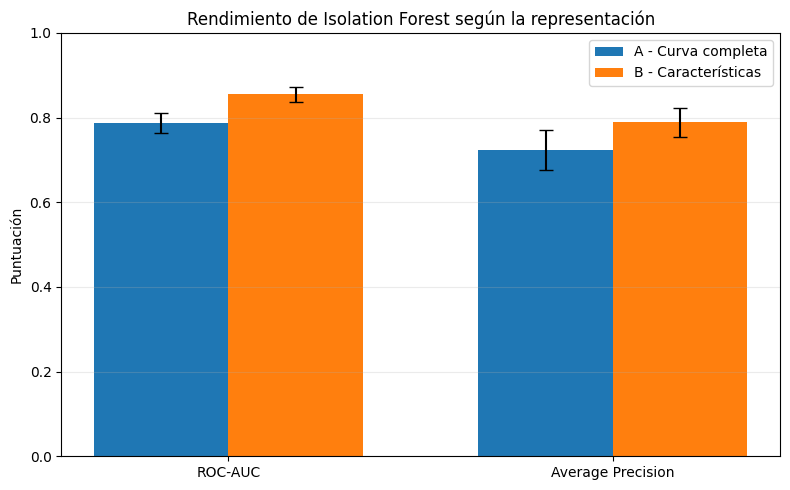

In [60]:
metrics = [
    "ROC-AUC",
    "Average Precision"
]

A_means = [
    if_A_results["ROC-AUC"].mean(),
    if_A_results["Average Precision"].mean()
]

B_means = [
    if_B_results["ROC-AUC"].mean(),
    if_B_results["Average Precision"].mean()
]

A_std = [
    if_A_results["ROC-AUC"].std(),
    if_A_results["Average Precision"].std()
]

B_std = [
    if_B_results["ROC-AUC"].std(),
    if_B_results["Average Precision"].std()
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width/2,
    A_means,
    width,
    yerr=A_std,
    capsize=5,
    label="A - Curva completa"
)

ax.bar(
    x + width/2,
    B_means,
    width,
    yerr=B_std,
    capsize=5,
    label="B - Características"
)

ax.set_ylabel("Puntuación")
ax.set_title(
    "Rendimiento de Isolation Forest según la representación"
)

ax.set_xticks(x)
ax.set_xticklabels(metrics)

ax.set_ylim(0, 1)

ax.legend()
ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()

Guerdar Imagen

In [61]:
fig_path = (
    OUTPUT_DIR
    / "TFM_08A_isolation_forest_A_vs_B.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print(fig_path)

/content/drive/MyDrive/14MBID_TFM/resultados/TFM_08A_isolation_forest_A_vs_B.png


#***CELDA 60 — Importaciones y función de evaluación***

#TFM-09 — One-Class SVM

In [62]:
# @title
# ============================================================
# TFM-09
# One-Class SVM
# Entrenamiento solo con curvas normales
# ============================================================

from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


def evaluate_oneclass_svm(
    X,
    representation_name,
    nu=0.05
):

    records = []

    for fold, indices in internal_folds.items():

        train_idx = indices["train_idx"]
        val_idx = indices["val_idx"]

        # ----------------------------------------------------
        # Seleccionar SOLO curvas normales de entrenamiento
        # ----------------------------------------------------

        train_normal_mask = (
            y_dev[train_idx] == 0
        )

        normal_train_idx = (
            train_idx[train_normal_mask]
        )

        X_train_normal = X[
            normal_train_idx
        ]

        X_val = X[
            val_idx
        ]

        y_val = y_dev[
            val_idx
        ]

        # ----------------------------------------------------
        # Escalado
        # Ajustado SOLO con normales de entrenamiento
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_normal
        )

        X_val_scaled = scaler.transform(
            X_val
        )

        # ----------------------------------------------------
        # One-Class SVM
        # ----------------------------------------------------

        model = OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=nu,
            cache_size=500
        )

        model.fit(
            X_train_scaled
        )

        # decision_function:
        # positivo = inlier
        # negativo = outlier
        #
        # Invertimos signo:
        # mayor score = más anómalo

        anomaly_score = -model.decision_function(
            X_val_scaled
        )

        roc_auc = roc_auc_score(
            y_val,
            anomaly_score
        )

        avg_precision = average_precision_score(
            y_val,
            anomaly_score
        )

        support_fraction = (
            model.n_support_[0]
            / len(X_train_scaled)
        )

        records.append({
            "Representación":
                representation_name,

            "Fold":
                fold,

            "Normales entrenamiento":
                len(X_train_scaled),

            "ROC-AUC":
                roc_auc,

            "Average Precision":
                avg_precision,

            "Fracción vectores soporte":
                support_fraction
        })

    return pd.DataFrame(records)

#***CELDA 61 — One-Class SVM con Representación A***

In [63]:
# @title
ocsvm_A_results = evaluate_oneclass_svm(
    X_curve_dev,
    "A - Curva completa",
    nu=0.05
)

display(
    ocsvm_A_results.round(4)
)

print("\nMEDIA:")
print(
    ocsvm_A_results[
        [
            "ROC-AUC",
            "Average Precision",
            "Fracción vectores soporte"
        ]
    ]
    .mean()
    .round(4)
)

print("\nDESVIACIÓN ESTÁNDAR:")
print(
    ocsvm_A_results[
        [
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .std()
    .round(4)
)

,Representación,Fold,Normales entrenamiento,ROC-AUC,Average Precision,Fracción vectores soporte
0,A - Curva completa,1,3942,0.8320,0.8002,0.0629
1,A - Curva completa,2,3912,0.8492,0.8226,0.0580
2,A - Curva completa,3,4045,0.9037,0.9022,0.0623
3,A - Curva completa,4,3888,0.8466,0.8021,0.0612
4,A - Curva completa,5,3985,0.8752,0.8723,0.0600



MEDIA:
ROC-AUC                      0.8613
Average Precision            0.8399
Fracción vectores soporte    0.0609
dtype: float64

DESVIACIÓN ESTÁNDAR:
ROC-AUC              0.0283
Average Precision    0.0453
dtype: float64


#***CELDA 62 — One-Class SVM con Representación B***

In [64]:
# @title
ocsvm_B_results = evaluate_oneclass_svm(
    X_features_dev,
    "B - Características",
    nu=0.05
)

display(
    ocsvm_B_results.round(4)
)

print("\nMEDIA:")
print(
    ocsvm_B_results[
        [
            "ROC-AUC",
            "Average Precision",
            "Fracción vectores soporte"
        ]
    ]
    .mean()
    .round(4)
)

print("\nDESVIACIÓN ESTÁNDAR:")
print(
    ocsvm_B_results[
        [
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .std()
    .round(4)
)

,Representación,Fold,Normales entrenamiento,ROC-AUC,Average Precision,Fracción vectores soporte
0,B - Características,1,3942,0.9115,0.8914,0.0545
1,B - Características,2,3912,0.9481,0.9249,0.0547
2,B - Características,3,4045,0.9523,0.9461,0.0541
3,B - Características,4,3888,0.9393,0.9088,0.0545
4,B - Características,5,3985,0.9395,0.9342,0.0537



MEDIA:
ROC-AUC                      0.9382
Average Precision            0.9211
Fracción vectores soporte    0.0543
dtype: float64

DESVIACIÓN ESTÁNDAR:
ROC-AUC              0.0159
Average Precision    0.0215
dtype: float64


#***CELDA 63 — Comparación A vs. B***

In [65]:
# @title
ocsvm_results = pd.concat(
    [
        ocsvm_A_results,
        ocsvm_B_results
    ],
    ignore_index=True
)

ocsvm_summary = (
    ocsvm_results
    .groupby("Representación")
    .agg({
        "ROC-AUC": [
            "mean",
            "std"
        ],
        "Average Precision": [
            "mean",
            "std"
        ],
        "Fracción vectores soporte": [
            "mean"
        ]
    })
)

display(
    ocsvm_summary.round(4)
)

ROC-AUC         Average Precision          \
                       mean     std              mean     std   
Representación                                                  
A - Curva completa   0.8613  0.0283            0.8399  0.0453   
B - Características  0.9382  0.0159            0.9211  0.0215   

                    Fracción vectores soporte  
                                         mean  
Representación                                 
A - Curva completa                     0.0609  
B - Características                    0.0543

#***CELDA 64 — Diferencias fold a fold***

In [66]:
# @title
paired_ocsvm = pd.DataFrame({
    "Fold":
        ocsvm_A_results["Fold"],

    "ROC-AUC A":
        ocsvm_A_results["ROC-AUC"].values,

    "ROC-AUC B":
        ocsvm_B_results["ROC-AUC"].values,

    "Diferencia ROC-AUC":
        (
            ocsvm_B_results["ROC-AUC"].values
            - ocsvm_A_results["ROC-AUC"].values
        ),

    "AP A":
        ocsvm_A_results[
            "Average Precision"
        ].values,

    "AP B":
        ocsvm_B_results[
            "Average Precision"
        ].values,

    "Diferencia AP":
        (
            ocsvm_B_results[
                "Average Precision"
            ].values
            - ocsvm_A_results[
                "Average Precision"
            ].values
        )
})

display(
    paired_ocsvm.round(4)
)

print(
    "\nMejora media ROC-AUC B-A:",
    round(
        paired_ocsvm[
            "Diferencia ROC-AUC"
        ].mean(),
        4
    )
)

print(
    "Mejora media AP B-A:",
    round(
        paired_ocsvm[
            "Diferencia AP"
        ].mean(),
        4
    )
)

,Fold,ROC-AUC A,ROC-AUC B,Diferencia ROC-AUC,AP A,AP B,Diferencia AP
0,1,0.8320,0.9115,0.0796,0.8002,0.8914,0.0912
1,2,0.8492,0.9481,0.0989,0.8226,0.9249,0.1024
2,3,0.9037,0.9523,0.0487,0.9022,0.9461,0.0439
3,4,0.8466,0.9393,0.0926,0.8021,0.9088,0.1067
4,5,0.8752,0.9395,0.0644,0.8723,0.9342,0.0619



Mejora media ROC-AUC B-A: 0.0768
Mejora media AP B-A: 0.0812


#***CELDA 65 — Consolidar resultados actuales***

In [67]:
# ============================================================
# Resumen de resultados hasta TFM-09
# ============================================================

baseline_summary = pd.DataFrame({
    "Modelo": [
        "Isolation Forest",
        "Isolation Forest",
        "One-Class SVM",
        "One-Class SVM"
    ],

    "Representación": [
        "A - Curva completa",
        "B - Características",
        "A - Curva completa",
        "B - Características"
    ],

    "ROC-AUC media": [
        if_A_results["ROC-AUC"].mean(),
        if_B_results["ROC-AUC"].mean(),
        ocsvm_A_results["ROC-AUC"].mean(),
        ocsvm_B_results["ROC-AUC"].mean()
    ],

    "ROC-AUC DE": [
        if_A_results["ROC-AUC"].std(),
        if_B_results["ROC-AUC"].std(),
        ocsvm_A_results["ROC-AUC"].std(),
        ocsvm_B_results["ROC-AUC"].std()
    ],

    "Average Precision media": [
        if_A_results["Average Precision"].mean(),
        if_B_results["Average Precision"].mean(),
        ocsvm_A_results["Average Precision"].mean(),
        ocsvm_B_results["Average Precision"].mean()
    ],

    "Average Precision DE": [
        if_A_results["Average Precision"].std(),
        if_B_results["Average Precision"].std(),
        ocsvm_A_results["Average Precision"].std(),
        ocsvm_B_results["Average Precision"].std()
    ]
})

display(
    baseline_summary.round(4)
)

,Modelo,Representación,ROC-AUC media,ROC-AUC DE,Average Precision media,Average Precision DE
0,Isolation Forest,A - Curva completa,0.7870,0.0243,0.7229,0.0467
1,Isolation Forest,B - Características,0.8551,0.0180,0.7889,0.0338
2,One-Class SVM,A - Curva completa,0.8613,0.0283,0.8399,0.0453
3,One-Class SVM,B - Características,0.9382,0.0159,0.9211,0.0215


#***CELDA 66 — Función de evaluación LOF***

#TFM-10 — Local Outlier Factor

In [68]:
# ============================================================
# TFM-10
# Local Outlier Factor - Novelty Detection
# ============================================================

from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


def evaluate_lof(
    X,
    representation_name,
    n_neighbors=20
):

    records = []

    for fold, indices in internal_folds.items():

        train_idx = indices["train_idx"]
        val_idx = indices["val_idx"]

        # ----------------------------------------------------
        # SOLO curvas normales de entrenamiento
        # ----------------------------------------------------

        normal_mask = (
            y_dev[train_idx] == 0
        )

        normal_train_idx = (
            train_idx[normal_mask]
        )

        X_train_normal = X[
            normal_train_idx
        ]

        X_val = X[
            val_idx
        ]

        y_val = y_dev[
            val_idx
        ]

        # ----------------------------------------------------
        # Escalado ajustado exclusivamente con entrenamiento
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_normal
        )

        X_val_scaled = scaler.transform(
            X_val
        )

        # ----------------------------------------------------
        # Local Outlier Factor
        # novelty=True permite evaluar observaciones nuevas
        # ----------------------------------------------------

        model = LocalOutlierFactor(
            n_neighbors=n_neighbors,
            novelty=True,
            contamination="auto",
            n_jobs=-1
        )

        model.fit(
            X_train_scaled
        )

        # decision_function:
        # valores mayores = más normales
        #
        # Invertimos el signo:
        # valores mayores = más anómalos

        anomaly_score = -model.decision_function(
            X_val_scaled
        )

        roc_auc = roc_auc_score(
            y_val,
            anomaly_score
        )

        avg_precision = average_precision_score(
            y_val,
            anomaly_score
        )

        records.append({
            "Representación":
                representation_name,

            "Fold":
                fold,

            "Normales entrenamiento":
                len(X_train_normal),

            "ROC-AUC":
                roc_auc,

            "Average Precision":
                avg_precision
        })

    return pd.DataFrame(records)

#***CELDA 67 — LOF con Representación A***

In [69]:
# @title
lof_A_results = evaluate_lof(
    X_curve_dev,
    "A - Curva completa",
    n_neighbors=20
)

display(
    lof_A_results.round(4)
)

print("\nMEDIA:")
print(
    lof_A_results[
        [
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .mean()
    .round(4)
)

print("\nDESVIACIÓN ESTÁNDAR:")
print(
    lof_A_results[
        [
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .std()
    .round(4)
)

,Representación,Fold,Normales entrenamiento,ROC-AUC,Average Precision
0,A - Curva completa,1,3942,0.8698,0.8354
1,A - Curva completa,2,3912,0.8924,0.8577
2,A - Curva completa,3,4045,0.9286,0.9193
3,A - Curva completa,4,3888,0.8934,0.8455
4,A - Curva completa,5,3985,0.9043,0.8894



MEDIA:
ROC-AUC              0.8977
Average Precision    0.8695
dtype: float64

DESVIACIÓN ESTÁNDAR:
ROC-AUC              0.0213
Average Precision    0.0345
dtype: float64


#***CELDA 68 — LOF con Representación B***

In [70]:
# @title
lof_B_results = evaluate_lof(
    X_features_dev,
    "B - Características",
    n_neighbors=20
)

display(
    lof_B_results.round(4)
)

print("\nMEDIA:")
print(
    lof_B_results[
        [
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .mean()
    .round(4)
)

print("\nDESVIACIÓN ESTÁNDAR:")
print(
    lof_B_results[
        [
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .std()
    .round(4)
)

,Representación,Fold,Normales entrenamiento,ROC-AUC,Average Precision
0,B - Características,1,3942,0.9285,0.9096
1,B - Características,2,3912,0.9503,0.9298
2,B - Características,3,4045,0.9667,0.9594
3,B - Características,4,3888,0.9502,0.9243
4,B - Características,5,3985,0.9503,0.9459



MEDIA:
ROC-AUC              0.9492
Average Precision    0.9338
dtype: float64

DESVIACIÓN ESTÁNDAR:
ROC-AUC              0.0136
Average Precision    0.0193
dtype: float64


#***CELDA 69 — Comparación LOF A vs. B***

In [71]:
# @title
lof_results = pd.concat(
    [
        lof_A_results,
        lof_B_results
    ],
    ignore_index=True
)

lof_summary = (
    lof_results
    .groupby("Representación")
    .agg({
        "ROC-AUC": [
            "mean",
            "std"
        ],
        "Average Precision": [
            "mean",
            "std"
        ]
    })
)

display(
    lof_summary.round(4)
)

ROC-AUC         Average Precision        
                       mean     std              mean     std
Representación                                               
A - Curva completa   0.8977  0.0213            0.8695  0.0345
B - Características  0.9492  0.0136            0.9338  0.0193

#***CELDA 70 — Comparación global de los tres modelos***

In [72]:
# @title
all_model_results = pd.DataFrame({
    "Modelo": [
        "Isolation Forest",
        "Isolation Forest",
        "One-Class SVM",
        "One-Class SVM",
        "LOF",
        "LOF"
    ],

    "Representación": [
        "A - Curva completa",
        "B - Características",
        "A - Curva completa",
        "B - Características",
        "A - Curva completa",
        "B - Características"
    ],

    "ROC-AUC media": [
        if_A_results["ROC-AUC"].mean(),
        if_B_results["ROC-AUC"].mean(),
        ocsvm_A_results["ROC-AUC"].mean(),
        ocsvm_B_results["ROC-AUC"].mean(),
        lof_A_results["ROC-AUC"].mean(),
        lof_B_results["ROC-AUC"].mean()
    ],

    "ROC-AUC DE": [
        if_A_results["ROC-AUC"].std(),
        if_B_results["ROC-AUC"].std(),
        ocsvm_A_results["ROC-AUC"].std(),
        ocsvm_B_results["ROC-AUC"].std(),
        lof_A_results["ROC-AUC"].std(),
        lof_B_results["ROC-AUC"].std()
    ],

    "AP media": [
        if_A_results["Average Precision"].mean(),
        if_B_results["Average Precision"].mean(),
        ocsvm_A_results["Average Precision"].mean(),
        ocsvm_B_results["Average Precision"].mean(),
        lof_A_results["Average Precision"].mean(),
        lof_B_results["Average Precision"].mean()
    ],

    "AP DE": [
        if_A_results["Average Precision"].std(),
        if_B_results["Average Precision"].std(),
        ocsvm_A_results["Average Precision"].std(),
        ocsvm_B_results["Average Precision"].std(),
        lof_A_results["Average Precision"].std(),
        lof_B_results["Average Precision"].std()
    ]
})

all_model_results = (
    all_model_results
    .sort_values(
        "ROC-AUC media",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    all_model_results.round(4)
)

,Modelo,Representación,ROC-AUC media,ROC-AUC DE,AP media,AP DE
0,LOF,B - Características,0.9492,0.0136,0.9338,0.0193
1,One-Class SVM,B - Características,0.9382,0.0159,0.9211,0.0215
2,LOF,A - Curva completa,0.8977,0.0213,0.8695,0.0345
3,One-Class SVM,A - Curva completa,0.8613,0.0283,0.8399,0.0453
4,Isolation Forest,B - Características,0.8551,0.0180,0.7889,0.0338
5,Isolation Forest,A - Curva completa,0.7870,0.0243,0.7229,0.0467


#***CELDA 71 — Función PCA + One-Class SVM***

#TFM-11 — PCA sobre la curva completa

In [73]:
# ============================================================
# TFM-11
# Representación C: Curva completa + PCA
# ============================================================

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


def evaluate_pca_ocsvm(
    X,
    variance=0.95,
    nu=0.05
):

    records = []

    for fold, indices in internal_folds.items():

        train_idx = indices["train_idx"]
        val_idx = indices["val_idx"]

        # Solo normales de entrenamiento
        normal_mask = (
            y_dev[train_idx] == 0
        )

        normal_train_idx = (
            train_idx[normal_mask]
        )

        X_train_normal = X[
            normal_train_idx
        ]

        X_val = X[
            val_idx
        ]

        y_val = y_dev[
            val_idx
        ]

        # --------------------------------------------
        # Escalado
        # --------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_normal
        )

        X_val_scaled = scaler.transform(
            X_val
        )

        # --------------------------------------------
        # PCA
        # --------------------------------------------

        pca = PCA(
            n_components=variance,
            svd_solver="full"
        )

        X_train_pca = pca.fit_transform(
            X_train_scaled
        )

        X_val_pca = pca.transform(
            X_val_scaled
        )

        # --------------------------------------------
        # One-Class SVM
        # --------------------------------------------

        model = OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=nu,
            cache_size=500
        )

        model.fit(
            X_train_pca
        )

        anomaly_score = (
            -model.decision_function(
                X_val_pca
            )
        )

        records.append({
            "Fold": fold,

            "Componentes PCA":
                pca.n_components_,

            "Varianza explicada":
                pca.explained_variance_ratio_.sum(),

            "ROC-AUC":
                roc_auc_score(
                    y_val,
                    anomaly_score
                ),

            "Average Precision":
                average_precision_score(
                    y_val,
                    anomaly_score
                )
        })

    return pd.DataFrame(records)

#***CELDA 72 — Ejecutar PCA + One-Class SVM***

In [74]:
# @title
pca_ocsvm_results = evaluate_pca_ocsvm(
    X_curve_dev,
    variance=0.95,
    nu=0.05
)

display(
    pca_ocsvm_results.round(4)
)

print("\nMEDIA:")
print(
    pca_ocsvm_results[
        [
            "Componentes PCA",
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .mean()
    .round(4)
)

print("\nDESVIACIÓN ESTÁNDAR:")
print(
    pca_ocsvm_results[
        [
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .std()
    .round(4)
)

,Fold,Componentes PCA,Varianza explicada,ROC-AUC,Average Precision
0,1,89,0.9503,0.8101,0.7886
1,2,86,0.9502,0.8244,0.8079
2,3,87,0.9506,0.8807,0.8902
3,4,86,0.9507,0.8059,0.7777
4,5,86,0.9504,0.8453,0.8552



MEDIA:
Componentes PCA      86.8000
ROC-AUC               0.8333
Average Precision     0.8239
dtype: float64

DESVIACIÓN ESTÁNDAR:
ROC-AUC              0.0307
Average Precision    0.0474
dtype: float64


#***CELDA 73 — PCA + LOF***

In [75]:
from sklearn.neighbors import LocalOutlierFactor


def evaluate_pca_lof(
    X,
    variance=0.95,
    n_neighbors=20
):

    records = []

    for fold, indices in internal_folds.items():

        train_idx = indices["train_idx"]
        val_idx = indices["val_idx"]

        normal_mask = (
            y_dev[train_idx] == 0
        )

        normal_train_idx = (
            train_idx[normal_mask]
        )

        X_train_normal = X[
            normal_train_idx
        ]

        X_val = X[
            val_idx
        ]

        y_val = y_dev[
            val_idx
        ]

        # --------------------------------------------
        # Escalado
        # --------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_normal
        )

        X_val_scaled = scaler.transform(
            X_val
        )

        # --------------------------------------------
        # PCA
        # --------------------------------------------

        pca = PCA(
            n_components=variance,
            svd_solver="full"
        )

        X_train_pca = pca.fit_transform(
            X_train_scaled
        )

        X_val_pca = pca.transform(
            X_val_scaled
        )

        # --------------------------------------------
        # LOF
        # --------------------------------------------

        model = LocalOutlierFactor(
            n_neighbors=n_neighbors,
            novelty=True,
            contamination="auto",
            n_jobs=-1
        )

        model.fit(
            X_train_pca
        )

        anomaly_score = (
            -model.decision_function(
                X_val_pca
            )
        )

        records.append({
            "Fold": fold,

            "Componentes PCA":
                pca.n_components_,

            "Varianza explicada":
                pca.explained_variance_ratio_.sum(),

            "ROC-AUC":
                roc_auc_score(
                    y_val,
                    anomaly_score
                ),

            "Average Precision":
                average_precision_score(
                    y_val,
                    anomaly_score
                )
        })

    return pd.DataFrame(records)

#***CELDA 74 — Ejecutar PCA + LOF***

In [76]:
# @title
pca_lof_results = evaluate_pca_lof(
    X_curve_dev,
    variance=0.95,
    n_neighbors=20
)

display(
    pca_lof_results.round(4)
)

print("\nMEDIA:")
print(
    pca_lof_results[
        [
            "Componentes PCA",
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .mean()
    .round(4)
)

print("\nDESVIACIÓN ESTÁNDAR:")
print(
    pca_lof_results[
        [
            "ROC-AUC",
            "Average Precision"
        ]
    ]
    .std()
    .round(4)
)

,Fold,Componentes PCA,Varianza explicada,ROC-AUC,Average Precision
0,1,89,0.9503,0.8311,0.8079
1,2,86,0.9502,0.8393,0.8173
2,3,87,0.9506,0.8869,0.8914
3,4,86,0.9507,0.8162,0.7840
4,5,86,0.9504,0.8460,0.8476



MEDIA:
Componentes PCA      86.8000
ROC-AUC               0.8439
Average Precision     0.8296
dtype: float64

DESVIACIÓN ESTÁNDAR:
ROC-AUC              0.0265
Average Precision    0.0414
dtype: float64


#***CELDA 75 — Comparar A, B y C***

In [77]:
# @title
representation_comparison = pd.DataFrame({
    "Modelo": [
        "One-Class SVM",
        "One-Class SVM",
        "One-Class SVM",
        "LOF",
        "LOF",
        "LOF"
    ],

    "Representación": [
        "A - Curva completa",
        "B - Características",
        "C - PCA 95%",
        "A - Curva completa",
        "B - Características",
        "C - PCA 95%"
    ],

    "ROC-AUC": [
        ocsvm_A_results["ROC-AUC"].mean(),
        ocsvm_B_results["ROC-AUC"].mean(),
        pca_ocsvm_results["ROC-AUC"].mean(),

        lof_A_results["ROC-AUC"].mean(),
        lof_B_results["ROC-AUC"].mean(),
        pca_lof_results["ROC-AUC"].mean()
    ],

    "Average Precision": [
        ocsvm_A_results[
            "Average Precision"
        ].mean(),

        ocsvm_B_results[
            "Average Precision"
        ].mean(),

        pca_ocsvm_results[
            "Average Precision"
        ].mean(),

        lof_A_results[
            "Average Precision"
        ].mean(),

        lof_B_results[
            "Average Precision"
        ].mean(),

        pca_lof_results[
            "Average Precision"
        ].mean()
    ]
})

display(
    representation_comparison.round(4)
)

,Modelo,Representación,ROC-AUC,Average Precision
0,One-Class SVM,A - Curva completa,0.8613,0.8399
1,One-Class SVM,B - Características,0.9382,0.9211
2,One-Class SVM,C - PCA 95%,0.8333,0.8239
3,LOF,A - Curva completa,0.8977,0.8695
4,LOF,B - Características,0.9492,0.9338
5,LOF,C - PCA 95%,0.8439,0.8296


#***CELDA 76 — Barrido de n_neighbors***

## TFM-12 — Optimización de Local Outlier Factor

In [78]:
# @title
# ============================================================
# TFM-12
# Ajuste de n_neighbors para LOF
# Representación B exclusivamente
# ============================================================

lof_k_grid = [
    5,
    10,
    15,
    20,
    30,
    40,
    60,
    80,
    100
]

lof_tuning_records = []
lof_tuning_folds = {}

for k in lof_k_grid:

    results_k = evaluate_lof(
        X_features_dev,
        f"B - Características | k={k}",
        n_neighbors=k
    )

    lof_tuning_folds[k] = results_k

    lof_tuning_records.append({
        "n_neighbors": k,

        "ROC-AUC media":
            results_k["ROC-AUC"].mean(),

        "ROC-AUC DE":
            results_k["ROC-AUC"].std(),

        "AP media":
            results_k["Average Precision"].mean(),

        "AP DE":
            results_k["Average Precision"].std()
    })


lof_tuning = pd.DataFrame(
    lof_tuning_records
)

lof_tuning = (
    lof_tuning
    .sort_values(
        [
            "AP media",
            "ROC-AUC media"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    lof_tuning.round(4)
)

,n_neighbors,ROC-AUC media,ROC-AUC DE,AP media,AP DE
0,15,0.9487,0.0135,0.9340,0.0193
1,20,0.9492,0.0136,0.9338,0.0193
2,30,0.9495,0.0128,0.9326,0.0187
3,40,0.9484,0.0130,0.9305,0.0187
4,10,0.9451,0.0127,0.9295,0.0199
5,60,0.9470,0.0147,0.9274,0.0198
6,80,0.9456,0.0167,0.9248,0.0217
7,100,0.9444,0.0178,0.9227,0.0228
8,5,0.9287,0.0169,0.9134,0.0249


#***CELDA 77 — Seleccionar el mejor k***

In [79]:
ap_tolerance = 0.001

max_ap = lof_tuning["AP media"].max()

lof_candidates = lof_tuning[
    lof_tuning["AP media"] >= max_ap - ap_tolerance
].copy()

selected_lof = (
    lof_candidates
    .sort_values("ROC-AUC media", ascending=False)
    .iloc[0]
)

LOF_FINAL_K = int(selected_lof["n_neighbors"])

print("k seleccionado:", LOF_FINAL_K)
print("ROC-AUC medio:", round(selected_lof["ROC-AUC media"], 4))
print("AP medio:", round(selected_lof["AP media"], 4))

k seleccionado: 20
ROC-AUC medio: 0.9492
AP medio: 0.9338


#***CELDA 78 — Visualizar sensibilidad a n_neighbors***

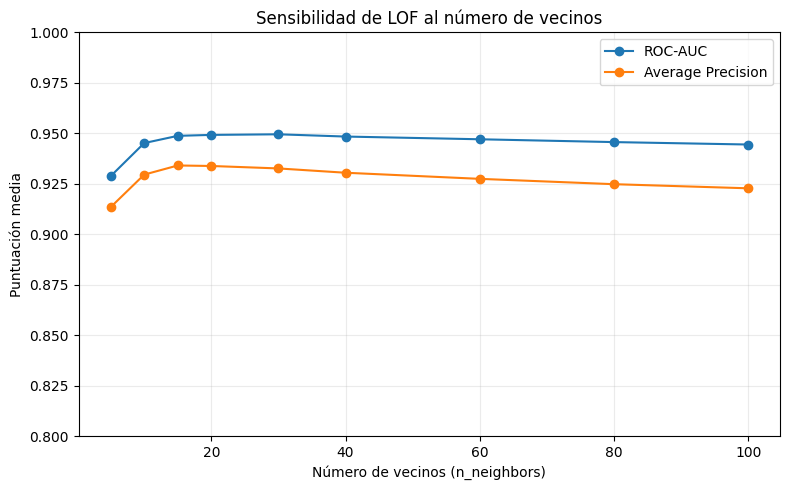

In [80]:
# @title
plot_tuning = (
    lof_tuning
    .sort_values("n_neighbors")
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    plot_tuning["n_neighbors"],
    plot_tuning["ROC-AUC media"],
    marker="o",
    label="ROC-AUC"
)

ax.plot(
    plot_tuning["n_neighbors"],
    plot_tuning["AP media"],
    marker="o",
    label="Average Precision"
)

ax.set_xlabel(
    "Número de vecinos (n_neighbors)"
)

ax.set_ylabel(
    "Puntuación media"
)

ax.set_title(
    "Sensibilidad de LOF al número de vecinos"
)

ax.set_ylim(
    0.80,
    1.00
)

ax.grid(
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()

#***CELDA 79 — Guardar resultados de optimización***

In [81]:
lof_tuning_path = (
    OUTPUT_DIR
    / "TFM_12_LOF_tuning.csv"
)

lof_tuning.to_csv(
    lof_tuning_path,
    index=False
)

print(
    "Resultados guardados en:"
)

print(
    lof_tuning_path
)

Resultados guardados en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_12_LOF_tuning.csv


#***CELDA 80 — Grid de hiperparámetros***

#TFM-13 — Optimización de One-Class SVM

In [82]:
# ============================================================
# TFM-13
# Optimización controlada de One-Class SVM
# Representación B
# ============================================================

nu_grid = [
    0.01,
    0.025,
    0.05,
    0.10,
    0.15
]

gamma_multipliers = [
    0.25,
    0.50,
    1.00,
    2.00,
    4.00
]

print(
    "Combinaciones:",
    len(nu_grid) * len(gamma_multipliers)
)

Combinaciones: 25


#***CELDA 81 — Función para evaluar una combinación***

In [83]:
def evaluate_ocsvm_config(
    X,
    nu,
    gamma_multiplier
):

    records = []

    for fold, indices in internal_folds.items():

        train_idx = indices["train_idx"]
        val_idx = indices["val_idx"]

        # --------------------------------------------
        # Solo normales de entrenamiento
        # --------------------------------------------

        normal_mask = (
            y_dev[train_idx] == 0
        )

        normal_train_idx = (
            train_idx[normal_mask]
        )

        X_train_normal = X[
            normal_train_idx
        ]

        X_val = X[
            val_idx
        ]

        y_val = y_dev[
            val_idx
        ]

        # --------------------------------------------
        # Escalado
        # --------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_normal
        )

        X_val_scaled = scaler.transform(
            X_val
        )

        # Equivalente al gamma='scale' de referencia
        gamma_base = (
            1.0
            /
            (
                X_train_scaled.shape[1]
                * X_train_scaled.var()
            )
        )

        gamma_value = (
            gamma_base
            * gamma_multiplier
        )

        # --------------------------------------------
        # One-Class SVM
        # --------------------------------------------

        model = OneClassSVM(
            kernel="rbf",
            gamma=gamma_value,
            nu=nu,
            cache_size=500
        )

        model.fit(
            X_train_scaled
        )

        anomaly_score = (
            -model.decision_function(
                X_val_scaled
            )
        )

        records.append({
            "Fold": fold,

            "nu": nu,

            "gamma_multiplier":
                gamma_multiplier,

            "gamma_real":
                gamma_value,

            "ROC-AUC":
                roc_auc_score(
                    y_val,
                    anomaly_score
                ),

            "Average Precision":
                average_precision_score(
                    y_val,
                    anomaly_score
                )
        })

    return pd.DataFrame(records)

#***CELDA 82 — Ejecutar la búsqueda***

In [84]:
# @title
ocsvm_tuning_records = []
ocsvm_tuning_folds = {}

for nu in nu_grid:

    for gamma_mult in gamma_multipliers:

        results = evaluate_ocsvm_config(
            X_features_dev,
            nu=nu,
            gamma_multiplier=gamma_mult
        )

        key = (
            nu,
            gamma_mult
        )

        ocsvm_tuning_folds[key] = results

        ocsvm_tuning_records.append({
            "nu": nu,

            "gamma_multiplier":
                gamma_mult,

            "ROC-AUC media":
                results["ROC-AUC"].mean(),

            "ROC-AUC DE":
                results["ROC-AUC"].std(),

            "AP media":
                results[
                    "Average Precision"
                ].mean(),

            "AP DE":
                results[
                    "Average Precision"
                ].std()
        })


ocsvm_tuning = pd.DataFrame(
    ocsvm_tuning_records
)

ocsvm_tuning = (
    ocsvm_tuning
    .sort_values(
        [
            "AP media",
            "ROC-AUC media"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    ocsvm_tuning.round(4)
)

,nu,gamma_multiplier,ROC-AUC media,ROC-AUC DE,AP media,AP DE
0,0.100,4.00,0.9466,0.0156,0.9296,0.0192
1,0.025,4.00,0.9444,0.0167,0.9293,0.0197
2,0.010,4.00,0.9444,0.0167,0.9293,0.0197
3,0.050,4.00,0.9440,0.0169,0.9288,0.0197
4,0.010,2.00,0.9458,0.0133,0.9287,0.0186
5,0.150,4.00,0.9475,0.0155,0.9286,0.0201
6,0.025,2.00,0.9454,0.0133,0.9282,0.0183
7,0.050,2.00,0.9443,0.0154,0.9269,0.0194
8,0.100,2.00,0.9446,0.0156,0.9257,0.0212
9,0.150,2.00,0.9447,0.0161,0.9247,0.0216


#***CELDA 83 — Mostrar las 10 mejores configuraciones***

In [85]:
display(
    ocsvm_tuning
    .head(10)
    .round(4)
)

,nu,gamma_multiplier,ROC-AUC media,ROC-AUC DE,AP media,AP DE
0,0.100,4.0,0.9466,0.0156,0.9296,0.0192
1,0.025,4.0,0.9444,0.0167,0.9293,0.0197
2,0.010,4.0,0.9444,0.0167,0.9293,0.0197
3,0.050,4.0,0.9440,0.0169,0.9288,0.0197
4,0.010,2.0,0.9458,0.0133,0.9287,0.0186
5,0.150,4.0,0.9475,0.0155,0.9286,0.0201
6,0.025,2.0,0.9454,0.0133,0.9282,0.0183
7,0.050,2.0,0.9443,0.0154,0.9269,0.0194
8,0.100,2.0,0.9446,0.0156,0.9257,0.0212
9,0.150,2.0,0.9447,0.0161,0.9247,0.0216


#***CELDA 84 — Comparación contra baseline***

In [86]:
# @title
baseline_ocsvm = ocsvm_tuning[
    (
        ocsvm_tuning["nu"] == 0.05
    )
    &
    (
        ocsvm_tuning[
            "gamma_multiplier"
        ] == 1.0
    )
]

best_ocsvm = (
    ocsvm_tuning.iloc[0]
)

print("MEJOR CONFIGURACIÓN")

print(
    "nu:",
    best_ocsvm["nu"]
)

print(
    "gamma multiplier:",
    best_ocsvm[
        "gamma_multiplier"
    ]
)

print(
    "ROC-AUC:",
    round(
        best_ocsvm[
            "ROC-AUC media"
        ],
        4
    )
)

print(
    "Average Precision:",
    round(
        best_ocsvm[
            "AP media"
        ],
        4
    )
)

print("\nBASELINE")

display(
    baseline_ocsvm.round(4)
)

MEJOR CONFIGURACIÓN
nu: 0.1
gamma multiplier: 4.0
ROC-AUC: 0.9466
Average Precision: 0.9296

BASELINE


,nu,gamma_multiplier,ROC-AUC media,ROC-AUC DE,AP media,AP DE
10,0.05,1.0,0.9382,0.0159,0.9211,0.0215


#***CELDA 85 — Mapa del rendimiento***

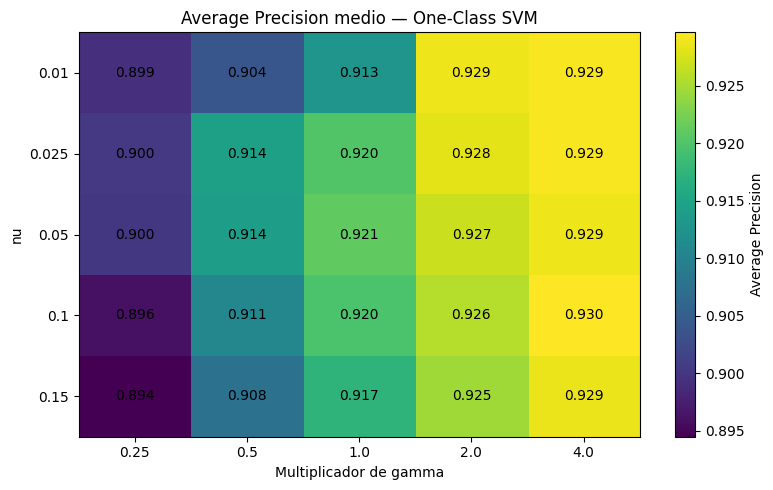

In [87]:
pivot_ap = (
    ocsvm_tuning
    .pivot(
        index="nu",
        columns="gamma_multiplier",
        values="AP media"
    )
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

im = ax.imshow(
    pivot_ap.values,
    aspect="auto"
)

ax.set_xticks(
    np.arange(
        len(pivot_ap.columns)
    )
)

ax.set_xticklabels(
    pivot_ap.columns
)

ax.set_yticks(
    np.arange(
        len(pivot_ap.index)
    )
)

ax.set_yticklabels(
    pivot_ap.index
)

ax.set_xlabel(
    "Multiplicador de gamma"
)

ax.set_ylabel(
    "nu"
)

ax.set_title(
    "Average Precision medio — One-Class SVM"
)

for i in range(
    len(pivot_ap.index)
):

    for j in range(
        len(pivot_ap.columns)
    ):

        ax.text(
            j,
            i,
            f"{pivot_ap.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Average Precision"
)

plt.tight_layout()
plt.show()

In [88]:
# CELDA 87 — Guardar FIGURA TFM-13A

fig_path = (
    OUTPUT_DIR
    / "TFM_13A_sensibilidad_OCSVM.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_13A_sensibilidad_OCSVM.png


#***CELDA 86 — Mejor configuración vs. baseline fold a fold***

In [89]:
# @title
# ============================================================
# TFM-13
# Comparación fold a fold:
# OCSVM optimizado vs. baseline
# ============================================================

best_key = (
    0.10,
    4.00
)

baseline_key = (
    0.05,
    1.00
)

best_fold_results = (
    ocsvm_tuning_folds[
        best_key
    ]
    .copy()
)

baseline_fold_results = (
    ocsvm_tuning_folds[
        baseline_key
    ]
    .copy()
)

ocsvm_paired_tuning = pd.DataFrame({
    "Fold":
        best_fold_results["Fold"],

    "ROC baseline":
        baseline_fold_results[
            "ROC-AUC"
        ].values,

    "ROC optimizado":
        best_fold_results[
            "ROC-AUC"
        ].values,

    "Δ ROC-AUC":
        (
            best_fold_results[
                "ROC-AUC"
            ].values
            -
            baseline_fold_results[
                "ROC-AUC"
            ].values
        ),

    "AP baseline":
        baseline_fold_results[
            "Average Precision"
        ].values,

    "AP optimizado":
        best_fold_results[
            "Average Precision"
        ].values,

    "Δ AP":
        (
            best_fold_results[
                "Average Precision"
            ].values
            -
            baseline_fold_results[
                "Average Precision"
            ].values
        )
})

display(
    ocsvm_paired_tuning.round(4)
)

print(
    "\nFolds con mejora en ROC-AUC:",
    (
        ocsvm_paired_tuning[
            "Δ ROC-AUC"
        ] > 0
    ).sum(),
    "/ 5"
)

print(
    "Folds con mejora en AP:",
    (
        ocsvm_paired_tuning[
            "Δ AP"
        ] > 0
    ).sum(),
    "/ 5"
)

print(
    "\nMejora media ROC-AUC:",
    round(
        ocsvm_paired_tuning[
            "Δ ROC-AUC"
        ].mean(),
        4
    )
)

print(
    "Mejora media AP:",
    round(
        ocsvm_paired_tuning[
            "Δ AP"
        ].mean(),
        4
    )
)

,Fold,ROC baseline,ROC optimizado,Δ ROC-AUC,AP baseline,AP optimizado,Δ AP
0,1,0.9115,0.9202,0.0086,0.8914,0.9014,0.0100
1,2,0.9481,0.9504,0.0023,0.9249,0.9276,0.0027
2,3,0.9523,0.9592,0.0068,0.9461,0.9520,0.0060
3,4,0.9393,0.9568,0.0175,0.9088,0.9251,0.0163
4,5,0.9395,0.9466,0.0071,0.9342,0.9421,0.0079



Folds con mejora en ROC-AUC: 5 / 5
Folds con mejora en AP: 5 / 5

Mejora media ROC-AUC: 0.0085
Mejora media AP: 0.0086


#***CELDA 87 — Registrar configuración final candidata***

In [90]:
OCSVM_FINAL_NU = 0.10
OCSVM_FINAL_GAMMA_MULT = 4.00

LOF_FINAL_K = 20

print(
    "Candidato One-Class SVM:"
)
print(
    f"nu = {OCSVM_FINAL_NU}"
)
print(
    f"gamma multiplier = "
    f"{OCSVM_FINAL_GAMMA_MULT}"
)

print(
    "\nCandidato LOF:"
)
print(
    f"n_neighbors = {LOF_FINAL_K}"
)

Candidato One-Class SVM:
nu = 0.1
gamma multiplier = 4.0

Candidato LOF:
n_neighbors = 20


#***CELDA 88 — Métricas de clasificación***

## TFM-14 — Selección del umbral de decisión

In [91]:
# ============================================================
# TFM-14
# Selección de umbral usando exclusivamente desarrollo
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)


def classification_metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    return {
        "Precision":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "Especificidad":
            specificity,

        "F1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

#***CELDA 89 — Grid de percentiles***

In [92]:
threshold_quantiles = [
    0.90,
    0.925,
    0.95,
    0.975,
    0.99
]

print(
    "Percentiles evaluados:",
    threshold_quantiles
)

Percentiles evaluados: [0.9, 0.925, 0.95, 0.975, 0.99]


#***CELDA 90 — Función para One-Class SVM***

In [93]:
def evaluate_ocsvm_thresholds(
    X,
    quantiles
):

    records = []

    for fold, indices in internal_folds.items():

        train_idx = indices["train_idx"]
        val_idx = indices["val_idx"]

        # --------------------------------------------
        # Solo normales de entrenamiento
        # --------------------------------------------

        normal_mask = (
            y_dev[train_idx] == 0
        )

        normal_train_idx = (
            train_idx[normal_mask]
        )

        X_train_normal = X[
            normal_train_idx
        ]

        X_val = X[
            val_idx
        ]

        y_val = y_dev[
            val_idx
        ]

        # --------------------------------------------
        # Escalado
        # --------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_normal
        )

        X_val_scaled = scaler.transform(
            X_val
        )

        # --------------------------------------------
        # Gamma definitivo
        # --------------------------------------------

        gamma_base = (
            1.0
            /
            (
                X_train_scaled.shape[1]
                * X_train_scaled.var()
            )
        )

        gamma_value = (
            gamma_base
            * OCSVM_FINAL_GAMMA_MULT
        )

        # --------------------------------------------
        # Modelo definitivo
        # --------------------------------------------

        model = OneClassSVM(
            kernel="rbf",
            nu=OCSVM_FINAL_NU,
            gamma=gamma_value,
            cache_size=500
        )

        model.fit(
            X_train_scaled
        )

        # Mayor valor = más anómalo
        train_scores = (
            -model.decision_function(
                X_train_scaled
            )
        )

        val_scores = (
            -model.decision_function(
                X_val_scaled
            )
        )

        # --------------------------------------------
        # Evaluación de percentiles
        # --------------------------------------------

        for q in quantiles:

            threshold = np.quantile(
                train_scores,
                q
            )

            y_pred = (
                val_scores >= threshold
            ).astype(int)

            metrics = classification_metrics(
                y_val,
                y_pred
            )

            records.append({
                "Modelo": "One-Class SVM",
                "Fold": fold,
                "Quantile": q,
                "Threshold": threshold,
                **metrics
            })

    return pd.DataFrame(records)

#***CELDA 91 — Función para LOF***

In [94]:
def evaluate_lof_thresholds(
    X,
    quantiles
):

    records = []

    for fold, indices in internal_folds.items():

        train_idx = indices["train_idx"]
        val_idx = indices["val_idx"]

        normal_mask = (
            y_dev[train_idx] == 0
        )

        normal_train_idx = (
            train_idx[normal_mask]
        )

        X_train_normal = X[
            normal_train_idx
        ]

        X_val = X[
            val_idx
        ]

        y_val = y_dev[
            val_idx
        ]

        # --------------------------------------------
        # Escalado
        # --------------------------------------------

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_normal
        )

        X_val_scaled = scaler.transform(
            X_val
        )

        # --------------------------------------------
        # LOF definitivo
        # --------------------------------------------

        model = LocalOutlierFactor(
            n_neighbors=LOF_FINAL_K,
            novelty=True,
            contamination="auto",
            n_jobs=-1
        )

        model.fit(
            X_train_scaled
        )

        # En entrenamiento:
        # negative_outlier_factor_:
        # mayor = más normal
        #
        # Invertimos:
        # mayor = más anómalo

        train_scores = (
            -model.negative_outlier_factor_
        )

        # En datos nuevos:
        # score_samples:
        # mayor = más normal
        #
        # Invertimos

        val_scores = (
            -model.score_samples(
                X_val_scaled
            )
        )

        for q in quantiles:

            threshold = np.quantile(
                train_scores,
                q
            )

            y_pred = (
                val_scores >= threshold
            ).astype(int)

            metrics = classification_metrics(
                y_val,
                y_pred
            )

            records.append({
                "Modelo": "LOF",
                "Fold": fold,
                "Quantile": q,
                "Threshold": threshold,
                **metrics
            })

    return pd.DataFrame(records)

#**CELDA 92 — Ejecutar selección de umbral***

In [95]:
ocsvm_threshold_results = (
    evaluate_ocsvm_thresholds(
        X_features_dev,
        threshold_quantiles
    )
)

lof_threshold_results = (
    evaluate_lof_thresholds(
        X_features_dev,
        threshold_quantiles
    )
)

threshold_results = pd.concat(
    [
        ocsvm_threshold_results,
        lof_threshold_results
    ],
    ignore_index=True
)

print(
    "Evaluaciones realizadas:",
    len(threshold_results)
)

Evaluaciones realizadas: 50


#***CELDA 93 — Resumen por modelo y percentil***

In [96]:
# @title
threshold_summary = (
    threshold_results
    .groupby(
        [
            "Modelo",
            "Quantile"
        ]
    )
    .agg({
        "Precision": [
            "mean",
            "std"
        ],

        "Recall": [
            "mean",
            "std"
        ],

        "Especificidad": [
            "mean",
            "std"
        ],

        "F1": [
            "mean",
            "std"
        ],

        "Balanced Accuracy": [
            "mean",
            "std"
        ]
    })
    .reset_index()
)

threshold_summary.columns = [
    "Modelo",
    "Quantile",

    "Precision media",
    "Precision DE",

    "Recall medio",
    "Recall DE",

    "Especificidad media",
    "Especificidad DE",

    "F1 medio",
    "F1 DE",

    "Balanced Accuracy media",
    "Balanced Accuracy DE"
]

display(
    threshold_summary.round(4)
)

,Modelo,Quantile,Precision media,Precision DE,Recall medio,Recall DE,Especificidad media,Especificidad DE,F1 medio,F1 DE,Balanced Accuracy media,Balanced Accuracy DE
0,LOF,0.900,0.8003,0.0341,0.8797,0.0404,0.8791,0.0194,0.8375,0.0279,0.8794,0.0156
1,LOF,0.925,0.8404,0.0260,0.8563,0.0448,0.9103,0.0139,0.8478,0.0285,0.8833,0.0181
2,LOF,0.950,0.8837,0.0136,0.8188,0.0542,0.9400,0.0125,0.8493,0.0318,0.8794,0.0230
3,LOF,0.975,0.9303,0.0213,0.7616,0.0504,0.9673,0.0157,0.8366,0.0294,0.8645,0.0208
4,LOF,0.990,0.9648,0.0194,0.6841,0.0587,0.9853,0.0109,0.7992,0.0368,0.8347,0.0257
5,One-Class SVM,0.900,0.7814,0.0339,0.8944,0.0308,0.8597,0.0328,0.8337,0.0265,0.8771,0.0169
6,One-Class SVM,0.925,0.7876,0.0339,0.8899,0.0316,0.8651,0.0336,0.8352,0.0259,0.8775,0.0161
7,One-Class SVM,0.950,0.8377,0.0366,0.8535,0.0448,0.9063,0.0308,0.8449,0.0306,0.8799,0.0208
8,One-Class SVM,0.975,0.9012,0.0314,0.7918,0.0684,0.9494,0.0262,0.8414,0.0389,0.8706,0.0282
9,One-Class SVM,0.990,0.9560,0.0282,0.6740,0.0861,0.9801,0.0196,0.7872,0.0499,0.8271,0.0346


#**CELDA 94 — Selección provisional por F1***

In [97]:
# @title
best_threshold_configs = (
    threshold_summary
    .sort_values(
        [
            "Modelo",
            "F1 medio",
            "Balanced Accuracy media"
        ],
        ascending=[
            True,
            False,
            False
        ]
    )
    .groupby(
        "Modelo",
        as_index=False
    )
    .first()
)

display(
    best_threshold_configs.round(4)
)

,Modelo,Quantile,Precision media,Precision DE,Recall medio,Recall DE,Especificidad media,Especificidad DE,F1 medio,F1 DE,Balanced Accuracy media,Balanced Accuracy DE
0,LOF,0.95,0.8837,0.0136,0.8188,0.0542,0.9400,0.0125,0.8493,0.0318,0.8794,0.0230
1,One-Class SVM,0.95,0.8377,0.0366,0.8535,0.0448,0.9063,0.0308,0.8449,0.0306,0.8799,0.0208


#***CELDA 95 — Curva F1 según percentil***

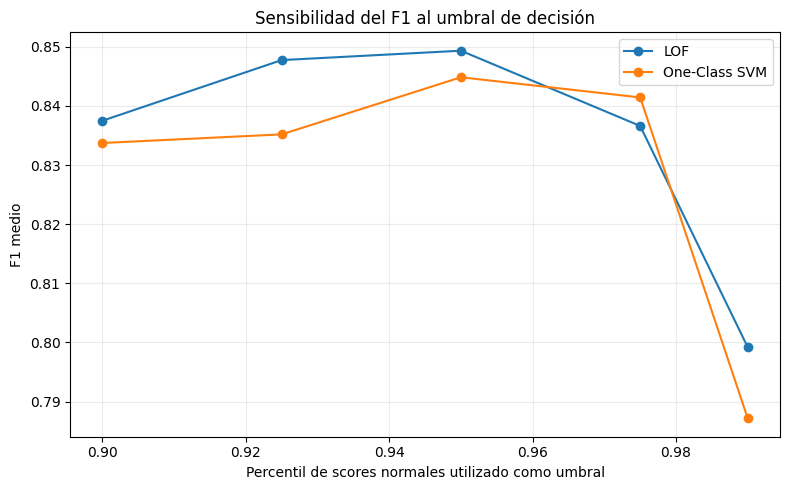

In [98]:
# @title
fig, ax = plt.subplots(
    figsize=(8, 5)
)

for model_name in [
    "LOF",
    "One-Class SVM"
]:

    model_data = (
        threshold_summary[
            threshold_summary["Modelo"]
            == model_name
        ]
        .sort_values("Quantile")
    )

    ax.plot(
        model_data["Quantile"],
        model_data["F1 medio"],
        marker="o",
        label=model_name
    )

ax.set_xlabel(
    "Percentil de scores normales utilizado como umbral"
)

ax.set_ylabel(
    "F1 medio"
)

ax.set_title(
    "Sensibilidad del F1 al umbral de decisión"
)

ax.grid(
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()

In [99]:
# CELDA 96 — Guardar FIGURA TFM-14A

fig_path = (
    OUTPUT_DIR
    / "TFM_14A_sensibilidad_F1_umbral.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_14A_sensibilidad_F1_umbral.png


In [100]:
# gaurda tabla de CELDA 93 - Resumen Promedio de Percentil
threshold_path = (
    OUTPUT_DIR
    / "TFM_14_threshold_summary.csv"
)

threshold_summary.to_csv(
    threshold_path,
    index=False
)

print(threshold_path)

/content/drive/MyDrive/14MBID_TFM/resultados/TFM_14_threshold_summary.csv


#***CELDA 96 — Construir matrices del test***

# TFM-15
# Preparación del conjunto de test

In [101]:
# @title
# ============================================================
# TFM-15
# Preparación del conjunto de test
# SIN usar etiquetas para decisiones de modelado
# ============================================================

test_meta = (
    test_labels[
        [
            "sample_num",
            "indent_num",
            "is_anomaly",
            "path"
        ]
    ]
    .reset_index(drop=True)
    .copy()
)

n_test = len(test_meta)

X_depth_test = np.empty(
    (n_test, N_POINTS),
    dtype=np.float32
)

X_load_test = np.empty(
    (n_test, N_POINTS),
    dtype=np.float32
)

same_time_grid_test = True

for i, rel_path in enumerate(test_meta["path"]):

    curve = pd.read_csv(
        BASE_DIR / rel_path,
        usecols=[
            "depth_nm",
            "load_micro_N",
            "time_s"
        ]
    )

    if len(curve) != N_POINTS:
        raise ValueError(
            f"{rel_path}: "
            f"{len(curve)} puntos en lugar de {N_POINTS}"
        )

    depth = curve["depth_nm"].to_numpy(
        dtype=np.float32
    )

    load = curve["load_micro_N"].to_numpy(
        dtype=np.float32
    )

    time = curve["time_s"].to_numpy(
        dtype=np.float32
    )

    if (
        np.isnan(depth).any()
        or np.isnan(load).any()
        or np.isnan(time).any()
    ):
        raise ValueError(
            f"NaN detectado en {rel_path}"
        )

    X_depth_test[i] = depth
    X_load_test[i] = load

    if not np.allclose(
        time,
        time_reference,
        rtol=0,
        atol=1e-6
    ):
        same_time_grid_test = False


print("Curvas test cargadas:", n_test)

print(
    "Matriz profundidad:",
    X_depth_test.shape
)

print(
    "Matriz carga:",
    X_load_test.shape
)

print(
    "Misma malla temporal que desarrollo:",
    same_time_grid_test
)

Curvas test cargadas: 1920
Matriz profundidad: (1920, 400)
Matriz carga: (1920, 400)
Misma malla temporal que desarrollo: True


#***CELDA 97 — Construir Representación B del test***

In [102]:
# @title
test_feature_rows = []

for i in range(len(test_meta)):

    features = extract_curve_features(
        X_depth_test[i],
        X_load_test[i],
        time_reference
    )

    test_feature_rows.append(
        features
    )


X_features_test_df = pd.DataFrame(
    test_feature_rows
)

# Forzar exactamente el mismo orden de columnas
X_features_test_df = (
    X_features_test_df[
        X_features_dev_df.columns
    ]
)

X_features_test = (
    X_features_test_df
    .to_numpy(
        dtype=np.float32
    )
)

print(
    "Dimensiones Representación B test:",
    X_features_test.shape
)

print(
    "Valores NaN:",
    X_features_test_df
    .isna()
    .sum()
    .sum()
)

print(
    "Valores infinitos:",
    np.isinf(
        X_features_test
    ).sum()
)

print(
    "Mismas características que desarrollo:",
    list(X_features_test_df.columns)
    ==
    list(X_features_dev_df.columns)
)

Dimensiones Representación B test: (1920, 19)
Valores NaN: 0
Valores infinitos: 0
Mismas características que desarrollo: True


#***CELDA 98 — Preparar todo el entrenamiento normal de desarrollo***

In [103]:
# ============================================================
# Entrenamiento final:
# SOLO normales del conjunto de desarrollo
# ============================================================

dev_normal_mask = (
    y_dev == 0
)

X_dev_normal_final = (
    X_features_dev[
        dev_normal_mask
    ]
)

print(
    "Curvas normales disponibles para entrenamiento final:",
    len(X_dev_normal_final)
)

print(
    "Características:",
    X_dev_normal_final.shape[1]
)

Curvas normales disponibles para entrenamiento final: 4943
Características: 19


#***CELDA 99 — Ajustar scaler final***

In [104]:
# @title
# El scaler se ajusta SOLO con normales de desarrollo

final_scaler = StandardScaler()

X_dev_normal_scaled = (
    final_scaler.fit_transform(
        X_dev_normal_final
    )
)

print(
    "Matriz normal escalada:",
    X_dev_normal_scaled.shape
)

print(
    "Media global después del escalado:",
    round(
        float(
            X_dev_normal_scaled.mean()
        ),
        6
    )
)

print(
    "Desviación estándar global:",
    round(
        float(
            X_dev_normal_scaled.std()
        ),
        6
    )
)

Matriz normal escalada: (4943, 19)
Media global después del escalado: 0.0
Desviación estándar global: 1.0


#***CELDA 100 — Entrenar LOF final y fijar su umbral***

In [105]:
# @title
# ============================================================
# LOF FINAL
# ============================================================

LOF_FINAL_Q = 0.95

lof_final = LocalOutlierFactor(
    n_neighbors=LOF_FINAL_K,
    novelty=True,
    contamination="auto",
    n_jobs=-1
)

lof_final.fit(
    X_dev_normal_scaled
)

# Score de entrenamiento:
# mayor valor = más anómalo
lof_train_scores = (
    -lof_final.negative_outlier_factor_
)

LOF_FINAL_THRESHOLD = np.quantile(
    lof_train_scores,
    LOF_FINAL_Q
)

print(
    "LOF FINAL"
)

print(
    "n_neighbors:",
    LOF_FINAL_K
)

print(
    "Quantile:",
    LOF_FINAL_Q
)

print(
    "Threshold:",
    round(
        float(LOF_FINAL_THRESHOLD),
        6
    )
)

print(
    "Normales de entrenamiento por encima del umbral:",
    int(
        (
            lof_train_scores
            >= LOF_FINAL_THRESHOLD
        ).sum()
    )
)

LOF FINAL
n_neighbors: 20
Quantile: 0.95
Threshold: 1.309295
Normales de entrenamiento por encima del umbral: 248


#***CELDA 101 — Entrenar One-Class SVM final y fijar su umbral***

In [106]:
# @title
# ============================================================
# ONE-CLASS SVM FINAL
# ============================================================

OCSVM_FINAL_Q = 0.95

gamma_base_final = (
    1.0
    /
    (
        X_dev_normal_scaled.shape[1]
        *
        X_dev_normal_scaled.var()
    )
)

OCSVM_FINAL_GAMMA = (
    gamma_base_final
    *
    OCSVM_FINAL_GAMMA_MULT
)

ocsvm_final = OneClassSVM(
    kernel="rbf",
    nu=OCSVM_FINAL_NU,
    gamma=OCSVM_FINAL_GAMMA,
    cache_size=500
)

ocsvm_final.fit(
    X_dev_normal_scaled
)

ocsvm_train_scores = (
    -ocsvm_final.decision_function(
        X_dev_normal_scaled
    )
)

OCSVM_FINAL_THRESHOLD = np.quantile(
    ocsvm_train_scores,
    OCSVM_FINAL_Q
)

print(
    "ONE-CLASS SVM FINAL"
)

print(
    "nu:",
    OCSVM_FINAL_NU
)

print(
    "gamma base:",
    round(
        float(gamma_base_final),
        6
    )
)

print(
    "gamma final:",
    round(
        float(OCSVM_FINAL_GAMMA),
        6
    )
)

print(
    "Quantile:",
    OCSVM_FINAL_Q
)

print(
    "Threshold:",
    round(
        float(OCSVM_FINAL_THRESHOLD),
        6
    )
)

print(
    "Vectores soporte:",
    ocsvm_final.n_support_[0]
)

print(
    "Fracción de vectores soporte:",
    round(
        ocsvm_final.n_support_[0]
        /
        len(X_dev_normal_scaled),
        4
    )
)

ONE-CLASS SVM FINAL
nu: 0.1
gamma base: 0.052632
gamma final: 0.210526
Quantile: 0.95
Threshold: 0.801311
Vectores soporte: 589
Fracción de vectores soporte: 0.1192


#***CELDA 102 — Guardar los artefactos finales***

In [107]:
# @title
import joblib
import json

MODEL_DIR = (
    OUTPUT_DIR
    / "modelos_finales"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    final_scaler,
    MODEL_DIR / "TFM_final_scaler.joblib"
)

joblib.dump(
    lof_final,
    MODEL_DIR / "TFM_final_LOF.joblib"
)

joblib.dump(
    ocsvm_final,
    MODEL_DIR / "TFM_final_OCSVM.joblib"
)


final_config = {
    "representation": "B - 19 características",

    "LOF": {
        "n_neighbors":
            int(LOF_FINAL_K),

        "threshold_quantile":
            float(LOF_FINAL_Q),

        "threshold":
            float(LOF_FINAL_THRESHOLD)
    },

    "OneClassSVM": {
        "nu":
            float(OCSVM_FINAL_NU),

        "gamma_multiplier":
            float(
                OCSVM_FINAL_GAMMA_MULT
            ),

        "gamma_final":
            float(
                OCSVM_FINAL_GAMMA
            ),

        "threshold_quantile":
            float(OCSVM_FINAL_Q),

        "threshold":
            float(
                OCSVM_FINAL_THRESHOLD
            )
    },

    "development_normal_curves":
        int(
            len(X_dev_normal_scaled)
        ),

    "features":
        list(
            X_features_dev_df.columns
        )
}


with open(
    MODEL_DIR / "TFM_final_config.json",
    "w"
) as f:

    json.dump(
        final_config,
        f,
        indent=4
    )


print(
    "Artefactos guardados en:"
)

print(MODEL_DIR)

Artefactos guardados en:
/content/drive/MyDrive/14MBID_TFM/resultados/modelos_finales


#***CELDA 103 — Preparar el test final***

# TFM-16 EVALUACIÓN FINAL INDEPENDIENTE

In [108]:
# @title
# ============================================================
# TFM-16
# EVALUACIÓN FINAL INDEPENDIENTE
# ============================================================

y_test = (
    test_meta["is_anomaly"]
    .to_numpy(dtype=np.int8)
)

# Aplicar el scaler YA ajustado con normales de desarrollo
X_test_scaled = (
    final_scaler.transform(
        X_features_test
    )
)

print("Curvas de test:", len(y_test))
print("Características:", X_test_scaled.shape[1])

print(
    "Normales:",
    int((y_test == 0).sum())
)

print(
    "Anómalas:",
    int((y_test == 1).sum())
)

print(
    "% anomalías:",
    round(
        y_test.mean() * 100,
        2
    )
)

Curvas de test: 1920
Características: 19
Normales: 1248
Anómalas: 672
% anomalías: 35.0


#***CELDA 104 — Scores finales de LOF y OCSVM***

In [109]:
# @title
# ============================================================
# Scores de anomalía sobre TEST
# ============================================================

# LOF:
# score_samples alto = más normal
# invertimos signo
lof_test_scores = (
    -lof_final.score_samples(
        X_test_scaled
    )
)

# OCSVM:
# decision_function positivo = más normal
# invertimos signo
ocsvm_test_scores = (
    -ocsvm_final.decision_function(
        X_test_scaled
    )
)

# Clasificación usando los umbrales YA congelados
lof_test_pred = (
    lof_test_scores
    >= LOF_FINAL_THRESHOLD
).astype(int)

ocsvm_test_pred = (
    ocsvm_test_scores
    >= OCSVM_FINAL_THRESHOLD
).astype(int)

print("Scores y predicciones generados.")

print(
    "LOF - curvas clasificadas como anómalas:",
    int(lof_test_pred.sum())
)

print(
    "OCSVM - curvas clasificadas como anómalas:",
    int(ocsvm_test_pred.sum())
)

Scores y predicciones generados.
LOF - curvas clasificadas como anómalas: 632
OCSVM - curvas clasificadas como anómalas: 696


#***CELDA 105 — Métricas finales***

In [110]:
# @title
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


def final_model_metrics(
    model_name,
    y_true,
    scores,
    predictions
):

    class_metrics = classification_metrics(
        y_true,
        predictions
    )

    return {
        "Modelo": model_name,

        "ROC-AUC":
            roc_auc_score(
                y_true,
                scores
            ),

        "Average Precision":
            average_precision_score(
                y_true,
                scores
            ),

        **class_metrics
    }


lof_final_metrics = final_model_metrics(
    "LOF",
    y_test,
    lof_test_scores,
    lof_test_pred
)

ocsvm_final_metrics = final_model_metrics(
    "One-Class SVM",
    y_test,
    ocsvm_test_scores,
    ocsvm_test_pred
)


final_test_results = pd.DataFrame(
    [
        lof_final_metrics,
        ocsvm_final_metrics
    ]
)

display(
    final_test_results.round(4)
)

,Modelo,ROC-AUC,Average Precision,Precision,Recall,Especificidad,F1,Balanced Accuracy,TN,FP,FN,TP
0,LOF,0.9352,0.9098,0.8323,0.7827,0.9151,0.8067,0.8489,1142,106,146,526
1,One-Class SVM,0.9375,0.9123,0.8147,0.8438,0.8966,0.8289,0.8702,1119,129,105,567


#***CELDA 106 — Comparar validación vs. test***

In [111]:
# @title
validation_vs_test = pd.DataFrame({
    "Modelo": [
        "LOF",
        "One-Class SVM"
    ],

    "ROC-AUC validación": [
        lof_B_results[
            "ROC-AUC"
        ].mean(),

        best_fold_results[
            "ROC-AUC"
        ].mean()
    ],

    "ROC-AUC test": [
        lof_final_metrics[
            "ROC-AUC"
        ],

        ocsvm_final_metrics[
            "ROC-AUC"
        ]
    ],

    "AP validación": [
        lof_B_results[
            "Average Precision"
        ].mean(),

        best_fold_results[
            "Average Precision"
        ].mean()
    ],

    "AP test": [
        lof_final_metrics[
            "Average Precision"
        ],

        ocsvm_final_metrics[
            "Average Precision"
        ]
    ]
})

validation_vs_test[
    "Δ ROC test-validación"
] = (
    validation_vs_test[
        "ROC-AUC test"
    ]
    -
    validation_vs_test[
        "ROC-AUC validación"
    ]
)

validation_vs_test[
    "Δ AP test-validación"
] = (
    validation_vs_test[
        "AP test"
    ]
    -
    validation_vs_test[
        "AP validación"
    ]
)

display(
    validation_vs_test.round(4)
)

,Modelo,ROC-AUC validación,ROC-AUC test,AP validación,AP test,Δ ROC test-validación,Δ AP test-validación
0,LOF,0.9492,0.9352,0.9338,0.9098,-0.0140,-0.0239
1,One-Class SVM,0.9466,0.9375,0.9296,0.9123,-0.0091,-0.0173


#***CELDA 107 — Matriz de confusión LOF***

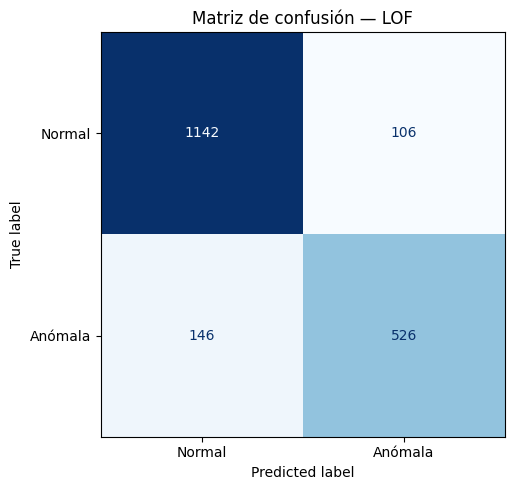

In [112]:
from sklearn.metrics import ConfusionMatrixDisplay

fig_lof, ax = plt.subplots(
    figsize=(5.5, 5)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lof_test_pred,
    display_labels=[
        "Normal",
        "Anómala"
    ],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(
    "Matriz de confusión — LOF"
)

plt.tight_layout()
plt.show()

In [113]:
fig_path = (
    OUTPUT_DIR
    / "TFM_16A_matriz_confusion_LOF.png"
)

fig_lof.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print(fig_path)

/content/drive/MyDrive/14MBID_TFM/resultados/TFM_16A_matriz_confusion_LOF.png


#***CELDA 108 — Matriz de confusión OCSVM***

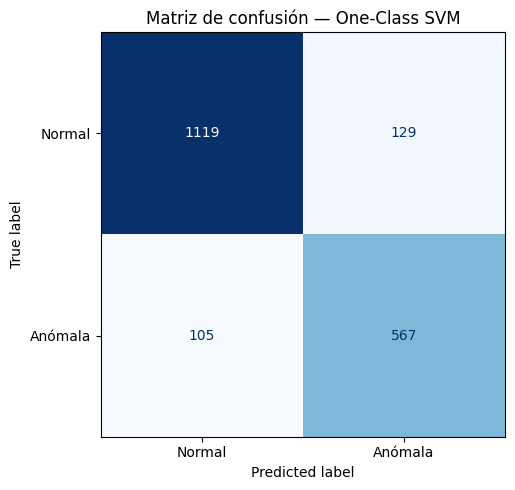

In [114]:
fig_ocsvm, ax = plt.subplots(
    figsize=(5.5, 5)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    ocsvm_test_pred,
    display_labels=[
        "Normal",
        "Anómala"
    ],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(
    "Matriz de confusión — One-Class SVM"
)

plt.tight_layout()
plt.show()

In [115]:
fig_path = (
    OUTPUT_DIR
    / "TFM_16B_matriz_confusion_OCSVM.png"
)

fig_ocsvm.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print(fig_path)

/content/drive/MyDrive/14MBID_TFM/resultados/TFM_16B_matriz_confusion_OCSVM.png


#***CELDA 109 — Guardar resultados y predicciones***

In [116]:
final_results_path = (
    OUTPUT_DIR
    / "TFM_16_resultados_test_final.csv"
)

final_test_results.to_csv(
    final_results_path,
    index=False
)


test_predictions = (
    test_meta[
        [
            "sample_num",
            "indent_num",
            "is_anomaly",
            "path"
        ]
    ]
    .copy()
)

test_predictions[
    "LOF_score"
] = lof_test_scores

test_predictions[
    "LOF_pred"
] = lof_test_pred

test_predictions[
    "OCSVM_score"
] = ocsvm_test_scores

test_predictions[
    "OCSVM_pred"
] = ocsvm_test_pred


predictions_path = (
    OUTPUT_DIR
    / "TFM_16_predicciones_test.csv"
)

test_predictions.to_csv(
    predictions_path,
    index=False
)

print("Resultados:")
print(final_results_path)

print("\nPredicciones:")
print(predictions_path)

Resultados:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_16_resultados_test_final.csv

Predicciones:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_16_predicciones_test.csv


#***CELDA 110 — Preparar las categorías del test***

#TFM-17 — Rendimiento por tipo de anomalía

In [117]:
# @title
# ============================================================
# TFM-17
# Análisis del rendimiento por tipo de anomalía
# ============================================================

test_analysis = test_labels.reset_index(drop=True).copy()

test_analysis["LOF_pred"] = lof_test_pred
test_analysis["OCSVM_pred"] = ocsvm_test_pred

test_analysis["LOF_score"] = lof_test_scores
test_analysis["OCSVM_score"] = ocsvm_test_scores


# Presencia binaria de cada tipo de anomalía
for col in category_cols:

    test_analysis[
        f"{col}_present"
    ] = (
        test_analysis[col]
        .fillna(0)
        .gt(0)
        .astype(int)
    )


test_analysis["other_present"] = (
    test_analysis["other"]
    .fillna("0")
    .astype(str)
    .str.strip()
    .ne("0")
    .astype(int)
)

print(
    "Curvas disponibles:",
    len(test_analysis)
)

print(
    "Anómalas:",
    test_analysis["is_anomaly"].sum()
)

Curvas disponibles: 1920
Anómalas: 672


#***CELDA 111 — Recall por tipo de anomalía***

In [118]:
# @title
category_test_records = []

all_test_categories = (
    category_cols
    + ["other"]
)

for category in all_test_categories:

    if category == "other":
        presence_col = "other_present"
        display_name = "Otras anomalías"

    else:
        presence_col = f"{category}_present"
        display_name = category_names[category]

    mask = (
        test_analysis[presence_col] == 1
    )

    n_category = int(mask.sum())

    lof_detected = int(
        test_analysis.loc[
            mask,
            "LOF_pred"
        ].sum()
    )

    ocsvm_detected = int(
        test_analysis.loc[
            mask,
            "OCSVM_pred"
        ].sum()
    )

    category_test_records.append({
        "Categoría":
            display_name,

        "Casos en test":
            n_category,

        "Detectados LOF":
            lof_detected,

        "Recall LOF":
            (
                lof_detected / n_category
                if n_category > 0
                else np.nan
            ),

        "Detectados OCSVM":
            ocsvm_detected,

        "Recall OCSVM":
            (
                ocsvm_detected / n_category
                if n_category > 0
                else np.nan
            )
    })


category_test_performance = pd.DataFrame(
    category_test_records
)

category_test_performance = (
    category_test_performance
    .sort_values(
        "Casos en test",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    category_test_performance.round(4)
)

,Categoría,Casos en test,Detectados LOF,Recall LOF,Detectados OCSVM,Recall OCSVM
0,Desplazamiento de fuerza,296,275,0.9291,293,0.9899
1,Curvatura inusual en descarga,205,128,0.6244,137,0.6683
2,Curvatura inusual en carga,69,43,0.6232,53,0.7681
3,Muestra completamente anómala,64,63,0.9844,63,0.9844
4,Disminución del desplazamiento durante manteni...,42,33,0.7857,34,0.8095
5,Desplazamiento de posición,17,10,0.5882,12,0.7059
6,Penetración excesiva,13,7,0.5385,9,0.6923
7,Otras anomalías,9,4,0.4444,6,0.6667


#***CELDA 112 — Diferencia OCSVM vs. LOF por anomalía***

In [119]:
category_test_performance[
    "Δ Recall OCSVM-LOF"
] = (
    category_test_performance[
        "Recall OCSVM"
    ]
    -
    category_test_performance[
        "Recall LOF"
    ]
)

display(
    category_test_performance.round(4)
)

,Categoría,Casos en test,Detectados LOF,Recall LOF,Detectados OCSVM,Recall OCSVM,Δ Recall OCSVM-LOF
0,Desplazamiento de fuerza,296,275,0.9291,293,0.9899,0.0608
1,Curvatura inusual en descarga,205,128,0.6244,137,0.6683,0.0439
2,Curvatura inusual en carga,69,43,0.6232,53,0.7681,0.1449
3,Muestra completamente anómala,64,63,0.9844,63,0.9844,0.0000
4,Disminución del desplazamiento durante manteni...,42,33,0.7857,34,0.8095,0.0238
5,Desplazamiento de posición,17,10,0.5882,12,0.7059,0.1176
6,Penetración excesiva,13,7,0.5385,9,0.6923,0.1538
7,Otras anomalías,9,4,0.4444,6,0.6667,0.2222


#***CELDA 113 — Figura de recall por tipo de anomalía***

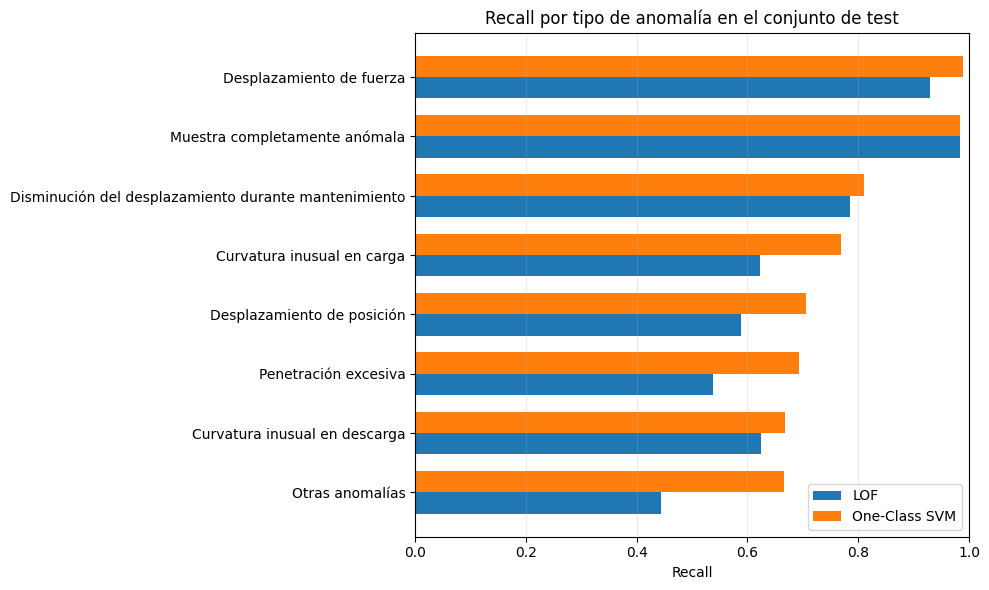

In [120]:
# @title
plot_category = (
    category_test_performance
    .sort_values(
        "Recall OCSVM",
        ascending=True
    )
)

y_pos = np.arange(
    len(plot_category)
)

height = 0.36

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.barh(
    y_pos - height/2,
    plot_category["Recall LOF"],
    height,
    label="LOF"
)

ax.barh(
    y_pos + height/2,
    plot_category["Recall OCSVM"],
    height,
    label="One-Class SVM"
)

ax.set_yticks(y_pos)

ax.set_yticklabels(
    plot_category["Categoría"]
)

ax.set_xlabel(
    "Recall"
)

ax.set_xlim(
    0,
    1
)

ax.set_title(
    "Recall por tipo de anomalía en el conjunto de test"
)

ax.grid(
    axis="x",
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()

In [121]:
fig_path = (
    OUTPUT_DIR
    / "TFM_17A_recall_por_tipo_anomalia.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print(fig_path)

/content/drive/MyDrive/14MBID_TFM/resultados/TFM_17A_recall_por_tipo_anomalia.png


#***CELDA 114 — Falsos negativos por modelo***

#TFM-18 — Analizar falsos negativos

In [122]:
lof_fn_mask = (
    (y_test == 1)
    &
    (lof_test_pred == 0)
)

ocsvm_fn_mask = (
    (y_test == 1)
    &
    (ocsvm_test_pred == 0)
)

print(
    "Falsos negativos LOF:",
    lof_fn_mask.sum()
)

print(
    "Falsos negativos OCSVM:",
    ocsvm_fn_mask.sum()
)

Falsos negativos LOF: 146
Falsos negativos OCSVM: 105


#***CELDA 115 — Composición de los falsos negativos***

In [123]:
# @title
fn_category_records = []

for category in all_test_categories:

    if category == "other":
        presence_col = "other_present"
        display_name = "Otras anomalías"

    else:
        presence_col = f"{category}_present"
        display_name = category_names[category]

    lof_fn_category = (
        lof_fn_mask
        &
        (
            test_analysis[
                presence_col
            ].to_numpy() == 1
        )
    ).sum()

    ocsvm_fn_category = (
        ocsvm_fn_mask
        &
        (
            test_analysis[
                presence_col
            ].to_numpy() == 1
        )
    ).sum()

    fn_category_records.append({
        "Categoría":
            display_name,

        "FN LOF":
            int(lof_fn_category),

        "FN OCSVM":
            int(ocsvm_fn_category)
    })


fn_category_table = pd.DataFrame(
    fn_category_records
)

display(
    fn_category_table
)

,Categoría,FN LOF,FN OCSVM
0,Muestra completamente anómala,1,1
1,Desplazamiento de fuerza,21,3
2,Desplazamiento de posición,7,5
3,Curvatura inusual en descarga,77,68
4,Curvatura inusual en carga,26,16
5,Disminución del desplazamiento durante manteni...,9,8
6,Penetración excesiva,6,4
7,Otras anomalías,5,3


#***CELDA 116 — Falsos positivos***

#TFM-19 — Analizar falsos positivos por muestra

In [124]:
lof_fp_mask = (
    (y_test == 0)
    &
    (lof_test_pred == 1)
)

ocsvm_fp_mask = (
    (y_test == 0)
    &
    (ocsvm_test_pred == 1)
)

print(
    "Falsos positivos LOF:",
    lof_fp_mask.sum()
)

print(
    "Falsos positivos OCSVM:",
    ocsvm_fp_mask.sum()
)

Falsos positivos LOF: 106
Falsos positivos OCSVM: 129


#***CELDA 117 — ¿Se concentran en algunas muestras?***

In [125]:
# @title
lof_fp_samples = (
    test_analysis.loc[
        lof_fp_mask,
        "sample_num"
    ]
    .value_counts()
    .rename("FP_LOF")
)

ocsvm_fp_samples = (
    test_analysis.loc[
        ocsvm_fp_mask,
        "sample_num"
    ]
    .value_counts()
    .rename("FP_OCSVM")
)

fp_by_sample = pd.concat(
    [
        lof_fp_samples,
        ocsvm_fp_samples
    ],
    axis=1
).fillna(0)

fp_by_sample = (
    fp_by_sample
    .astype(int)
    .sort_values(
        "FP_OCSVM",
        ascending=False
    )
)

display(
    fp_by_sample.head(15)
)

,FP_LOF,FP_OCSVM
sample_num,,
6806,16,20
5970,14,16
5915,9,14
6813,10,11
6846,3,10
6815,4,9
6800,5,8
6011,7,7
6270,2,6


#***CELDA 118 — Resumen completo por muestra***

#TFM-20 — Análisis de errores por muestra y metadatos

In [126]:
# @title
# ============================================================
# TFM-20
# Análisis de errores por muestra física
# ============================================================

sample_error_analysis = (
    test_analysis
    .groupby("sample_num")
    .agg(
        total_curves=("indent_num", "size"),
        real_anomalies=("is_anomaly", "sum"),
        LOF_predicted_anomalies=("LOF_pred", "sum"),
        OCSVM_predicted_anomalies=("OCSVM_pred", "sum")
    )
    .reset_index()
)

sample_error_analysis["real_normals"] = (
    sample_error_analysis["total_curves"]
    - sample_error_analysis["real_anomalies"]
)

display(
    sample_error_analysis.head()
)

,sample_num,total_curves,real_anomalies,LOF_predicted_anomalies,OCSVM_predicted_anomalies,real_normals
0,2666,64,27,30,27,37
1,4147,64,64,63,63,0
2,5915,64,26,31,39,38
3,5922,64,16,17,12,48
4,5970,64,28,40,43,36


#***CELDA 119 — Calcular FP y FN por muestra***

In [127]:
# @title
sample_errors = []

for sample in test_analysis["sample_num"].unique():

    data = test_analysis[
        test_analysis["sample_num"] == sample
    ]

    lof_fp = (
        (data["is_anomaly"] == 0)
        &
        (data["LOF_pred"] == 1)
    ).sum()

    lof_fn = (
        (data["is_anomaly"] == 1)
        &
        (data["LOF_pred"] == 0)
    ).sum()

    ocsvm_fp = (
        (data["is_anomaly"] == 0)
        &
        (data["OCSVM_pred"] == 1)
    ).sum()

    ocsvm_fn = (
        (data["is_anomaly"] == 1)
        &
        (data["OCSVM_pred"] == 0)
    ).sum()

    sample_errors.append({
        "sample_num": sample,
        "LOF_FP": int(lof_fp),
        "LOF_FN": int(lof_fn),
        "OCSVM_FP": int(ocsvm_fp),
        "OCSVM_FN": int(ocsvm_fn)
    })


sample_error_table = pd.DataFrame(
    sample_errors
)

sample_error_table = (
    sample_error_table
    .sort_values(
        "OCSVM_FP",
        ascending=False
    )
)

display(
    sample_error_table.head(15)
)

,sample_num,LOF_FP,LOF_FN,OCSVM_FP,OCSVM_FN
14,6806,16,4,20,1
20,5970,14,2,16,1
18,5915,9,4,14,1
15,6813,10,4,11,2
17,6846,3,6,10,3
16,6815,4,7,9,2
13,6800,5,2,8,0
21,6011,7,3,7,3
27,6270,2,8,6,6
19,5922,7,6,4,8


#***CELDA 120 — Añadir metadatos experimentales***

In [128]:
# @title
sample_metadata = (
    test_labels[
        [
            "sample_num",
            "solution",
            "current_density",
            "batch_num"
        ]
    ]
    .drop_duplicates(
        subset="sample_num"
    )
)

sample_error_metadata = (
    sample_error_table
    .merge(
        sample_metadata,
        on="sample_num",
        how="left"
    )
)

display(
    sample_error_metadata.head(15)
)

,sample_num,LOF_FP,LOF_FN,OCSVM_FP,OCSVM_FN,solution,current_density,batch_num
0,6806,16,4,20,1,NiFe1_stirred,35.0,626
1,5970,14,2,16,1,NiFe2_nostir,35.0,615
2,5915,9,4,14,1,NiFe2_nostir,1.0,615
3,6813,10,4,11,2,NiFe1_stirred,45.0,626
4,6846,3,6,10,3,NiFe1_stirred,125.0,626
5,6815,4,7,9,2,NiFe1_stirred,50.0,626
6,6800,5,2,8,0,NiFe1_stirred,30.0,626
7,6011,7,3,7,3,NiFe2_nostir,125.0,615
8,6270,2,8,6,6,NiFe4_nostir,90.0,622
9,5922,7,6,4,8,NiFe2_nostir,5.0,615


#***CELDA 121 — Tasas de error por muestra***

In [129]:
# @title
# ============================================================
# TFM-20
# Tasas normalizadas de error por muestra
# ============================================================

sample_denominators = (
    test_analysis
    .groupby("sample_num")
    .agg(
        real_normals=(
            "is_anomaly",
            lambda x: (x == 0).sum()
        ),
        real_anomalies=(
            "is_anomaly",
            lambda x: (x == 1).sum()
        )
    )
    .reset_index()
)

sample_error_rates = (
    sample_error_metadata
    .merge(
        sample_denominators,
        on="sample_num",
        how="left"
    )
)

sample_error_rates["LOF_FP_rate"] = (
    sample_error_rates["LOF_FP"]
    / sample_error_rates["real_normals"]
)

sample_error_rates["OCSVM_FP_rate"] = (
    sample_error_rates["OCSVM_FP"]
    / sample_error_rates["real_normals"]
)

sample_error_rates["LOF_FN_rate"] = (
    sample_error_rates["LOF_FN"]
    / sample_error_rates["real_anomalies"]
)

sample_error_rates["OCSVM_FN_rate"] = (
    sample_error_rates["OCSVM_FN"]
    / sample_error_rates["real_anomalies"]
)

display(
    sample_error_rates[
        sample_error_rates["real_normals"] > 0
    ]
    .sort_values(
        "OCSVM_FP_rate",
        ascending=False
    )
    .head(15)
    .round(4)
)

,sample_num,LOF_FP,LOF_FN,OCSVM_FP,OCSVM_FN,solution,current_density,batch_num,real_normals,real_anomalies,LOF_FP_rate,OCSVM_FP_rate,LOF_FN_rate,OCSVM_FN_rate
0,6806,16,4,20,1,NiFe1_stirred,35.0,626,36,28,0.4444,0.5556,0.1429,0.0357
1,5970,14,2,16,1,NiFe2_nostir,35.0,615,36,28,0.3889,0.4444,0.0714,0.0357
2,5915,9,4,14,1,NiFe2_nostir,1.0,615,38,26,0.2368,0.3684,0.1538,0.0385
7,6011,7,3,7,3,NiFe2_nostir,125.0,615,25,39,0.2800,0.2800,0.0769,0.0769
3,6813,10,4,11,2,NiFe1_stirred,45.0,626,45,19,0.2222,0.2444,0.2105,0.1053
5,6815,4,7,9,2,NiFe1_stirred,50.0,626,43,21,0.0930,0.2093,0.3333,0.0952
6,6800,5,2,8,0,NiFe1_stirred,30.0,626,41,23,0.1220,0.1951,0.0870,0.0000
4,6846,3,6,10,3,NiFe1_stirred,125.0,626,55,9,0.0545,0.1818,0.6667,0.3333
8,6270,2,8,6,6,NiFe4_nostir,90.0,622,49,15,0.0408,0.1224,0.5333,0.4000
10,6266,3,5,4,4,NiFe4_nostir,80.0,622,43,21,0.0698,0.0930,0.2381,0.1905


#***CELDA 122 — Función de resumen por metadato***

In [130]:
# @title
def summarize_errors_by_group(
    df,
    group_col
):

    records = []

    for value, group in df.groupby(
        group_col,
        dropna=False
    ):

        normals = (
            group["is_anomaly"] == 0
        ).sum()

        anomalies = (
            group["is_anomaly"] == 1
        ).sum()

        lof_fp = (
            (group["is_anomaly"] == 0)
            &
            (group["LOF_pred"] == 1)
        ).sum()

        lof_fn = (
            (group["is_anomaly"] == 1)
            &
            (group["LOF_pred"] == 0)
        ).sum()

        ocsvm_fp = (
            (group["is_anomaly"] == 0)
            &
            (group["OCSVM_pred"] == 1)
        ).sum()

        ocsvm_fn = (
            (group["is_anomaly"] == 1)
            &
            (group["OCSVM_pred"] == 0)
        ).sum()

        records.append({
            group_col: value,

            "Muestras":
                group["sample_num"].nunique(),

            "Curvas":
                len(group),

            "Normales":
                int(normals),

            "Anómalas":
                int(anomalies),

            "LOF_FP":
                int(lof_fp),

            "LOF_FP_rate":
                (
                    lof_fp / normals
                    if normals > 0
                    else np.nan
                ),

            "LOF_FN":
                int(lof_fn),

            "LOF_FN_rate":
                (
                    lof_fn / anomalies
                    if anomalies > 0
                    else np.nan
                ),

            "OCSVM_FP":
                int(ocsvm_fp),

            "OCSVM_FP_rate":
                (
                    ocsvm_fp / normals
                    if normals > 0
                    else np.nan
                ),

            "OCSVM_FN":
                int(ocsvm_fn),

            "OCSVM_FN_rate":
                (
                    ocsvm_fn / anomalies
                    if anomalies > 0
                    else np.nan
                )
        })

    return pd.DataFrame(records)

#***CELDA 123 — Errores por solución***

In [131]:
# @title
errors_by_solution = summarize_errors_by_group(
    test_analysis,
    "solution"
)

errors_by_solution = (
    errors_by_solution
    .sort_values(
        "OCSVM_FP_rate",
        ascending=False
    )
)

display(
    errors_by_solution.round(4)
)

,solution,Muestras,Curvas,Normales,Anómalas,LOF_FP,LOF_FP_rate,LOF_FN,LOF_FN_rate,OCSVM_FP,OCSVM_FP_rate,OCSVM_FN,OCSVM_FN_rate
3,NiFe2_nostir,4,256,147,109,37,0.2517,15,0.1376,41,0.2789,13,0.1193
2,NiFe1_stirred,6,384,268,116,38,0.1418,31,0.2672,58,0.2164,12,0.1034
5,NiFe4_nostir,3,192,145,47,6,0.0414,17,0.3617,12,0.0828,15,0.3191
0,NiFe0_nostir,2,128,37,91,3,0.0811,1,0.0110,1,0.0270,2,0.0220
1,NiFe1_nostir_1_contaminated,10,640,447,193,13,0.0291,45,0.2332,12,0.0268,31,0.1606
4,NiFe3_nostir,3,192,114,78,3,0.0263,27,0.3462,3,0.0263,21,0.2692
6,NiFe5_nostir,2,128,90,38,6,0.0667,10,0.2632,2,0.0222,11,0.2895


#***CELDA 124 — Errores por lote***

In [132]:
errors_by_batch = summarize_errors_by_group(
    test_analysis,
    "batch_num"
)

errors_by_batch = (
    errors_by_batch
    .sort_values(
        "OCSVM_FP_rate",
        ascending=False
    )
)

display(
    errors_by_batch.round(4)
)

,batch_num,Muestras,Curvas,Normales,Anómalas,LOF_FP,LOF_FP_rate,LOF_FN,LOF_FN_rate,OCSVM_FP,OCSVM_FP_rate,OCSVM_FN,OCSVM_FN_rate
2,615,4,256,147,109,37,0.2517,15,0.1376,41,0.2789,13,0.1193
6,626,6,384,268,116,38,0.1418,31,0.2672,58,0.2164,12,0.1034
4,622,3,192,145,47,6,0.0414,17,0.3617,12,0.0828,15,0.3191
0,609,2,128,37,91,3,0.0811,1,0.0110,1,0.0270,2,0.0220
1,614,10,640,447,193,13,0.0291,45,0.2332,12,0.0268,31,0.1606
3,619,3,192,114,78,3,0.0263,27,0.3462,3,0.0263,21,0.2692
5,623,2,128,90,38,6,0.0667,10,0.2632,2,0.0222,11,0.2895


#***CELDA 125 — Concentración de FP en las muestras más problemáticas***

In [133]:
# @title
fp_rank = (
    sample_error_rates
    .sort_values(
        "OCSVM_FP",
        ascending=False
    )
)

total_ocsvm_fp = (
    sample_error_rates[
        "OCSVM_FP"
    ].sum()
)

for n in [3, 4, 5, 7, 10]:

    fp_top_n = (
        fp_rank
        .head(n)["OCSVM_FP"]
        .sum()
    )

    pct = (
        fp_top_n
        / total_ocsvm_fp
        * 100
    )

    print(
        f"Top {n} muestras: "
        f"{fp_top_n} FP "
        f"({pct:.2f} %)"
    )

Top 3 muestras: 50 FP (38.76 %)
Top 4 muestras: 61 FP (47.29 %)
Top 5 muestras: 71 FP (55.04 %)
Top 7 muestras: 88 FP (68.22 %)
Top 10 muestras: 105 FP (81.40 %)


#***CELDA 126 — Distancia al umbral OCSVM***

# TFM-21
# Selección reproducible de casos TP, TN, FP y FN

In [134]:
# @title
# ============================================================
# TFM-21
# Selección reproducible de casos TP, TN, FP y FN
# ============================================================

case_analysis = test_analysis.copy()

case_analysis["distance_to_threshold"] = (
    case_analysis["OCSVM_score"]
    - OCSVM_FINAL_THRESHOLD
)

case_analysis["case_type"] = np.select(
    [
        (case_analysis["is_anomaly"] == 1)
        & (case_analysis["OCSVM_pred"] == 1),

        (case_analysis["is_anomaly"] == 0)
        & (case_analysis["OCSVM_pred"] == 0),

        (case_analysis["is_anomaly"] == 0)
        & (case_analysis["OCSVM_pred"] == 1),

        (case_analysis["is_anomaly"] == 1)
        & (case_analysis["OCSVM_pred"] == 0)
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN"
    ],
    default="NA"
)

print(
    case_analysis["case_type"]
    .value_counts()
)

case_type
TN    1119
TP     567
FP     129
FN     105
Name: count, dtype: int64


#***CELDA 127 — Seleccionar cuatro casos***

In [135]:
# @title
# TP más claramente anómalo
tp_example = (
    case_analysis[
        case_analysis["case_type"] == "TP"
    ]
    .sort_values(
        "distance_to_threshold",
        ascending=False
    )
    .iloc[0]
)

# TN más claramente normal
tn_example = (
    case_analysis[
        case_analysis["case_type"] == "TN"
    ]
    .sort_values(
        "distance_to_threshold",
        ascending=True
    )
    .iloc[0]
)

# FP más próximo al umbral
fp_example = (
    case_analysis[
        case_analysis["case_type"] == "FP"
    ]
    .sort_values(
        "distance_to_threshold",
        ascending=True
    )
    .iloc[0]
)

# FN más próximo al umbral
fn_example = (
    case_analysis[
        case_analysis["case_type"] == "FN"
    ]
    .sort_values(
        "distance_to_threshold",
        ascending=False
    )
    .iloc[0]
)

selected_cases = pd.DataFrame(
    [
        tp_example,
        tn_example,
        fp_example,
        fn_example
    ]
)

display(
    selected_cases[
        [
            "case_type",
            "sample_num",
            "indent_num",
            "is_anomaly",
            "OCSVM_score",
            "distance_to_threshold",
            "path"
        ]
    ].round(4)
)

,case_type,sample_num,indent_num,is_anomaly,OCSVM_score,distance_to_threshold,path
1795,TP,6404,3,1,7.7925,6.9912,NiFe5_nostir/cd_15/sample_6404/623_6404_nanoin...
805,TN,6783,37,0,-3.6025,-4.4038,NiFe1_stirred/cd_10/sample_6783/626_6783_nanoi...
1035,FP,6815,11,0,0.8046,0.0033,NiFe1_stirred/cd_50/sample_6815/626_6815_nanoi...
1768,FN,6270,40,1,0.7436,-0.0577,NiFe4_nostir/cd_90/sample_6270/622_6270_nanoin...


#***CELDA 128 — Mostrar las etiquetas de anomalía de los casos***

In [136]:
display_cols = [
    "case_type",
    "sample_num",
    "indent_num"
] + category_cols + ["other"]

display(
    selected_cases[
        display_cols
    ]
)

,case_type,sample_num,indent_num,fully_anomalous_sample,force_offset,displacement_offset,unusual_unloading_curvature,unusual_loading_curvature,tip_displacement_decreases_at_holding,too_deep,other
1795,TP,6404,3,0,2,0,0,0,0,0,0
805,TN,6783,37,0,0,0,0,0,0,0,0
1035,FP,6815,11,0,0,0,0,0,0,0,0
1768,FN,6270,40,0,0,0,2,0,0,0,0


#***CELDA 129 — Curva normal de referencia por muestra***

In [137]:
# @title
# ============================================================
# TFM-21
# Referencia normal de la misma muestra
# ============================================================

def get_same_sample_normal_median(
    selected_row
):
    """
    Construye una curva mediana usando las curvas
    etiquetadas como normales de la misma muestra.
    Se excluye la propia indentación seleccionada.
    """

    sample_num = selected_row["sample_num"]
    indent_num = selected_row["indent_num"]

    normal_rows = test_analysis[
        (test_analysis["sample_num"] == sample_num)
        &
        (test_analysis["is_anomaly"] == 0)
        &
        (test_analysis["indent_num"] != indent_num)
    ]

    if len(normal_rows) == 0:
        return None

    depth_stack = []
    load_stack = []

    for _, row in normal_rows.iterrows():

        curve = load_curve(row)

        depth_stack.append(
            curve["depth_nm"].to_numpy()
        )

        load_stack.append(
            curve["load_micro_N"].to_numpy()
        )

    median_depth = np.median(
        np.vstack(depth_stack),
        axis=0
    )

    median_load = np.median(
        np.vstack(load_stack),
        axis=0
    )

    return {
        "depth": median_depth,
        "load": median_load,
        "n_normals": len(normal_rows)
    }

#***CELDA 130 — Comprobar las referencias disponibles***

In [138]:
# @title
case_references = {}

for _, row in selected_cases.iterrows():

    case_type = row["case_type"]

    reference = (
        get_same_sample_normal_median(
            row
        )
    )

    case_references[
        case_type
    ] = reference

    print(
        case_type,
        "| muestra:",
        row["sample_num"],
        "| curvas normales para referencia:",
        (
            reference["n_normals"]
            if reference is not None
            else 0
        )
    )

TP | muestra: 6404 | curvas normales para referencia: 38
TN | muestra: 6783 | curvas normales para referencia: 47
FP | muestra: 6815 | curvas normales para referencia: 42
FN | muestra: 6270 | curvas normales para referencia: 49


#***CELDA 131 — Figura TP / TN / FP / FN***

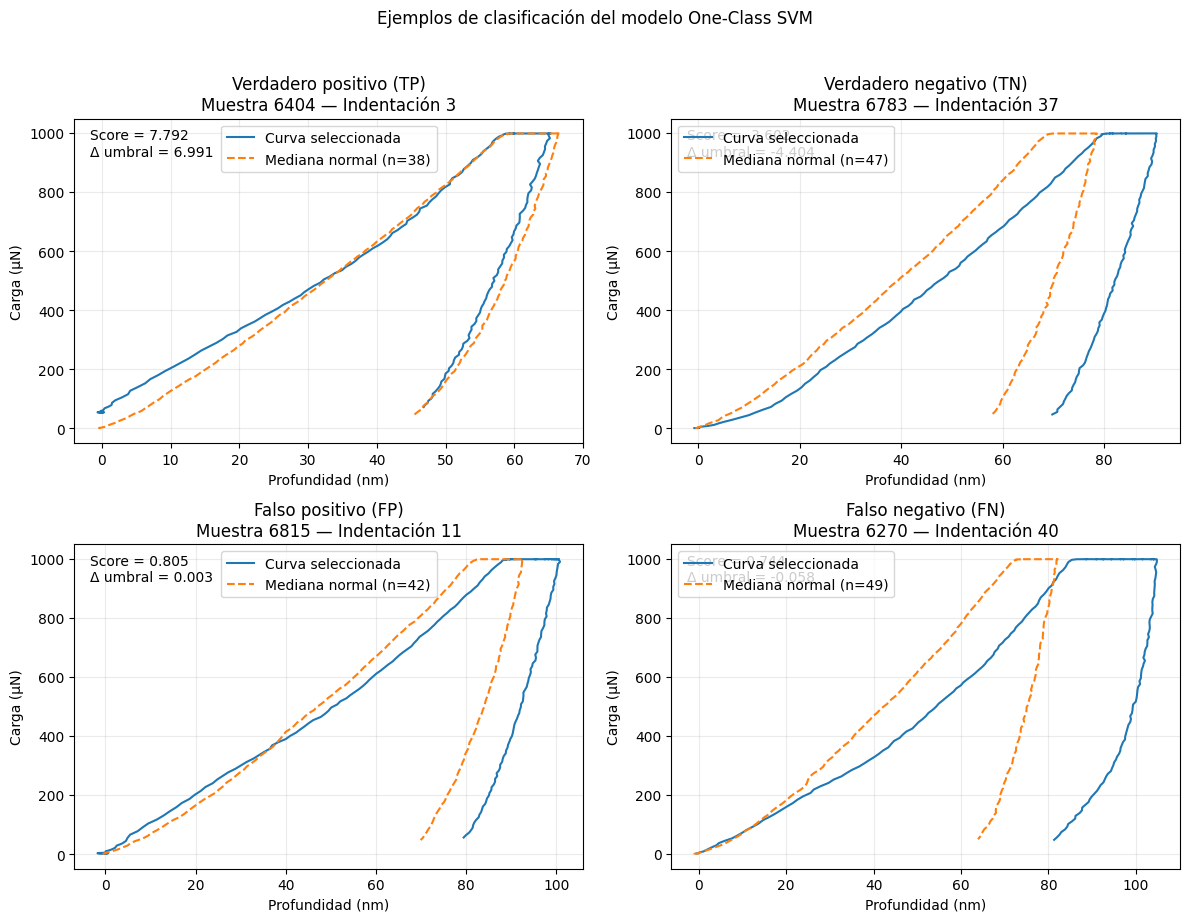

In [139]:
# ============================================================
# FIGURA TFM-21A
# Casos representativos del modelo final
# ============================================================

case_titles = {
    "TP": "Verdadero positivo (TP)",
    "TN": "Verdadero negativo (TN)",
    "FP": "Falso positivo (FP)",
    "FN": "Falso negativo (FN)"
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)

axes = axes.flatten()

ordered_cases = [
    "TP",
    "TN",
    "FP",
    "FN"
]

for ax, case_type in zip(
    axes,
    ordered_cases
):

    row = selected_cases[
        selected_cases["case_type"]
        == case_type
    ].iloc[0]

    curve = load_curve(row)

    reference = (
        case_references[
            case_type
        ]
    )

    # Curva seleccionada
    ax.plot(
        curve["depth_nm"],
        curve["load_micro_N"],
        label="Curva seleccionada"
    )

    # Mediana de normales de la misma muestra
    if reference is not None:

        ax.plot(
            reference["depth"],
            reference["load"],
            linestyle="--",
            label=(
                "Mediana normal "
                f"(n={reference['n_normals']})"
            )
        )

    ax.set_title(
        f"{case_titles[case_type]}\n"
        f"Muestra {row['sample_num']} — "
        f"Indentación {row['indent_num']}"
    )

    ax.set_xlabel(
        "Profundidad (nm)"
    )

    ax.set_ylabel(
        "Carga (µN)"
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend()

    # Score y distancia al umbral
    ax.text(
        0.03,
        0.97,
        (
            f"Score = {row['OCSVM_score']:.3f}\n"
            f"Δ umbral = "
            f"{row['distance_to_threshold']:.3f}"
        ),
        transform=ax.transAxes,
        verticalalignment="top"
    )

plt.suptitle(
    "Ejemplos de clasificación del modelo One-Class SVM",
    y=1.02
)

plt.tight_layout()
plt.show()

#***CELDA 132 — Guardar la figura***

In [140]:
fig_path = (
    OUTPUT_DIR
    / "TFM_21A_casos_TP_TN_FP_FN_OCSVM.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print(
    "Figura guardada en:"
)

print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_21A_casos_TP_TN_FP_FN_OCSVM.png


#***CELDA 133 — Obtener distribución normal de referencia***

In [141]:
def get_same_sample_normal_curves(selected_row):
    """
    Obtiene todas las curvas normales disponibles
    de la misma muestra, excluyendo la indentación
    seleccionada.
    """

    sample_num = selected_row["sample_num"]
    indent_num = selected_row["indent_num"]

    normal_rows = test_analysis[
        (test_analysis["sample_num"] == sample_num)
        &
        (test_analysis["is_anomaly"] == 0)
        &
        (test_analysis["indent_num"] != indent_num)
    ]

    curves = []

    for _, row in normal_rows.iterrows():

        curve = load_curve(row)

        curves.append({
            "depth":
                curve["depth_nm"].to_numpy(),

            "load":
                curve["load_micro_N"].to_numpy()
        })

    return curves

#***CELDA 134 — Figura final TP / TN / FP / FN mejorada***

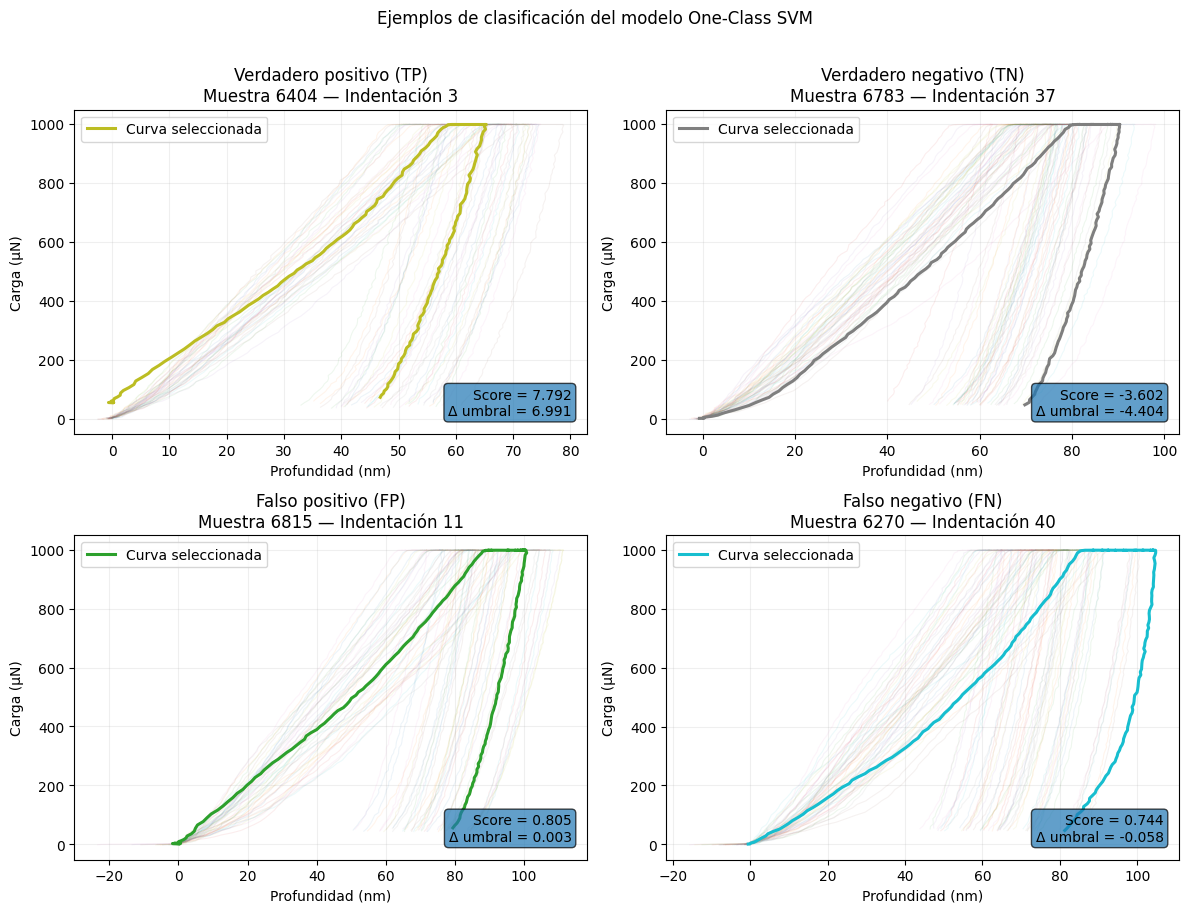

In [142]:
case_titles = {
    "TP": "Verdadero positivo (TP)",
    "TN": "Verdadero negativo (TN)",
    "FP": "Falso positivo (FP)",
    "FN": "Falso negativo (FN)"
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9)
)

axes = axes.flatten()

ordered_cases = [
    "TP",
    "TN",
    "FP",
    "FN"
]

for ax, case_type in zip(
    axes,
    ordered_cases
):

    row = selected_cases[
        selected_cases["case_type"]
        == case_type
    ].iloc[0]

    selected_curve = load_curve(row)

    normal_curves = (
        get_same_sample_normal_curves(
            row
        )
    )

    # Curvas normales de referencia
    for normal_curve in normal_curves:

        ax.plot(
            normal_curve["depth"],
            normal_curve["load"],
            alpha=0.08,
            linewidth=0.8
        )

    # Curva seleccionada
    ax.plot(
        selected_curve["depth_nm"],
        selected_curve["load_micro_N"],
        linewidth=2.2,
        label="Curva seleccionada"
    )

    ax.set_title(
        f"{case_titles[case_type]}\n"
        f"Muestra {row['sample_num']} — "
        f"Indentación {row['indent_num']}"
    )

    ax.set_xlabel(
        "Profundidad (nm)"
    )

    ax.set_ylabel(
        "Carga (µN)"
    )

    ax.grid(
        alpha=0.20
    )

    ax.text(
        0.97,
        0.05,
        (
            f"Score = {row['OCSVM_score']:.3f}\n"
            f"Δ umbral = "
            f"{row['distance_to_threshold']:.3f}"
        ),
        transform=ax.transAxes,
        horizontalalignment="right",
        verticalalignment="bottom",
        bbox=dict(
            boxstyle="round",
            alpha=0.7
        )
    )

    ax.legend(
        loc="upper left"
    )

plt.suptitle(
    "Ejemplos de clasificación del modelo One-Class SVM",
    y=1.01
)

plt.tight_layout()
plt.show()

In [143]:
# ============================================================
# Guardar FIGURA TFM-21A
# ============================================================

fig_path = (
    OUTPUT_DIR
    / "TFM_21A_casos_TP_TN_FP_FN_OCSVM_mejorada.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_21A_casos_TP_TN_FP_FN_OCSVM_mejorada.png


#***CELDA 135 — Zoom específico del falso negativo***

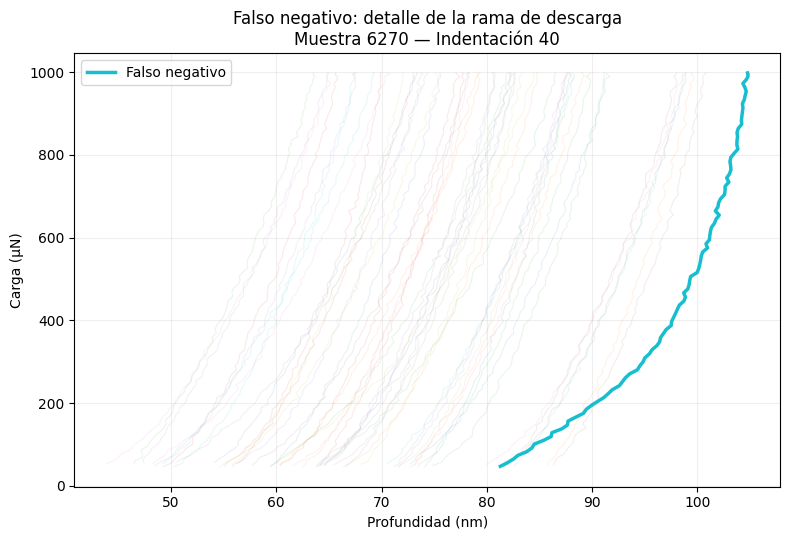

In [144]:
fn_row = selected_cases[
    selected_cases["case_type"]
    == "FN"
].iloc[0]

fn_curve = load_curve(
    fn_row
)

fn_normal_curves = (
    get_same_sample_normal_curves(
        fn_row
    )
)

fig_fn, ax = plt.subplots(
    figsize=(8, 5.5)
)

# Solo región de descarga
for normal_curve in fn_normal_curves:

    ax.plot(
        normal_curve["depth"][unloading_idx],
        normal_curve["load"][unloading_idx],
        alpha=0.10,
        linewidth=0.8
    )

ax.plot(
    fn_curve["depth_nm"].to_numpy()[unloading_idx],
    fn_curve["load_micro_N"].to_numpy()[unloading_idx],
    linewidth=2.5,
    label="Falso negativo"
)

ax.set_xlabel(
    "Profundidad (nm)"
)

ax.set_ylabel(
    "Carga (µN)"
)

ax.set_title(
    "Falso negativo: detalle de la rama de descarga\n"
    "Muestra 6270 — Indentación 40"
)

ax.grid(
    alpha=0.20
)

ax.legend()

plt.tight_layout()
plt.show()

In [145]:
# ============================================================
# Guardar FIGURA TFM-21B
# ============================================================

fig_fn_path = (
    OUTPUT_DIR
    / "TFM_21B_zoom_falso_negativo_descarga.png"
)

fig_fn.savefig(
    fig_fn_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figura guardada en:")
print(fig_fn_path)

Figura guardada en:
/content/drive/MyDrive/14MBID_TFM/resultados/TFM_21B_zoom_falso_negativo_descarga.png
